# x50 データの学習とテスト予測（グローバルモデル: 全種類を1つのモデルで、LightGBM / XGBoost）

- **作成者**: ImoZukushi
- **作成日**: 2026-10-21（2026-10-25 long 型の入力に変更、欠損に対応）
- **目的**: `notebook/003_feature_engineering_x50.ipynb` が出力した前処理済みの long 型のデータで、目的変数の全種類
  （`Y_cat` = Y1〜Y10）を **1つのモデル（グローバルモデル）** で学習し、テスト期間（2025年）を再帰予測する。学習結果・
  テスト結果・SHAP によるモデル解釈を図で確認し、種類ごとに別モデルを作る `004` と比べる。評価指標は MAE。
- **入力**（long 型。1行 = 日付 × 種類）: `data/processed/x50/x50_train_features.csv`, `data/processed/x50/x50_test_features.csv`
  （評価用に `data/synthetic/x50/dummy_x50_test_answer.csv`）
- **出力**: `outputs/experiments/x50_global_{モデル名}/{実行日時}/`（予測・MAE の表・図・SHAP・ログ）、
  MLflow（`mlruns/`）、ログファイル `outputs/logs/`
- **欠損**: 目的変数・説明変数に、散発的な欠損と連続した欠損がある（学習・テストの両方）。欠損は埋めず、目的変数が欠損の行は学習・評価から除く（「リークを防ぐための決まり」の「欠損」）
- **スクリプト版**: `scripts/train_predict_x50_global.py`（同じ処理を CLI で実行できる）。このノートブックは `scripts/` を
  import せず、同じ関数をノートブック内（「関数の定義」）で定義している。入力の読み込み・確認、図の部品は 004 と同じ関数。

**グローバルモデルとは:** long 型の学習データ（1行 = 日付 × 種類）をそのまま使い、種類の列 `Y_cat` を系列IDとして
特徴量に加えて、全種類の行で1つのモデルを学習する。データを共有できる（似た動きの種類から学べる）一方、
種類ごとに効く説明変数が違う場合は、その違いを「系列ID × 説明変数」の組み合わせとして学ぶ必要がある。

## リークを防ぐための決まり

| 段階 | 決まり | どこで確かめるか |
|---|---|---|
| 前処理 | 説明変数・日付の前処理は、003 で学習データだけを使って fit 済み。系列IDの整数化（`PandasOrdinalEncoder`）だけは、CVの各 fold の学習期間で fit する | 003 のリークの確認 / `modeling` の Pipeline |
| 入力 | テストデータに、目的変数（`Y`・`Y_raw`）も、その特徴量（`Y_lag_*`）も無いこと | 1. 読み込み（`load_inputs`） |
| 系列ごとの特徴量 | 目的変数の特徴量は系列（種類）ごとに作る。各行の特徴量は**その行の種類自身**のラグ等だけで、他の種類の値は混ざらない。系列ごとに作り直した値が、003 で種類ごとに作ったCSVの値と一致することを確かめる | 2. 学習用データとリークの確認（`prepare`） |
| 目的変数の特徴量 | 検証・テスト期間は**再帰予測の中で**、全系列を1日ずつ同時に進めながら予測値から作り直す | `modeling.forecasting` |
| CV | 日付で区切る時系列CV（全系列で同じ境目）。境目より前だけで学習し、境目以降を**実測値を使わずに**再帰予測して評価する | 2. の fold の期間の確認 |
| 評価 | テストの正解ファイルは、テスト予測が終わった後の MAE の計算にだけ使う | 3. `collect_predictions` |
| 欠損 | 欠損は前後の値で埋めない（補間はその日より後の値を使うため）。目的変数が欠損の行は、学習（目的変数として）・評価から除き、ラグの元としては欠損のまま残す。移動平均は窓内の観測値だけで平均する（`ROLLING_MIN_PERIODS`。003 と違う値なら `prepare` でエラー）。説明変数・ラグの欠損はモデルに任せる | 2. 学習（`prepare`）/ `modeling.forecasting` / `modeling.metrics` |

In [1]:
import datetime as dt
import hashlib
import logging
import re
import shutil
import sys
import time
import warnings
from collections.abc import Sequence
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

# pyproject.toml を目印にリポジトリルートを探し、src/ をimportパスに追加する
# （scripts/ の関数は import せず、このノートブック内で定義する）
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

# ipywidgets が無い環境で tqdm が出す警告（進捗バーの表示だけの問題）は出さない
warnings.filterwarnings("ignore", message="IProgress not found")

# src/ 配下のモジュール（上でパスを追加した後にimportする必要がある）
from modeling.config import ExperimentConfig  # noqa: E402
from modeling.dataset import Dataset  # noqa: E402
from modeling.experiment import ExperimentResult, prepare_dataset, run_experiment  # noqa: E402
from modeling.forecasting import ForecastCVResult, make_builder  # noqa: E402
from modeling.metrics import get_metric  # noqa: E402
from modeling.tracking import MLflowTracker, NullTracker, Tracker  # noqa: E402
from util.csv_io import read_csv_auto  # noqa: E402
from util.paths import data_dir, ensure_parent_dir, get_repo_root, outputs_dir  # noqa: E402
from util.plotting import add_caption, ensure_japanese_font  # noqa: E402

pd.set_option("display.max_columns", 20)

## パラメータ

papermill で実行するときは `-p 名前 値` で上書きできる（このセルに `parameters` タグを付けている）。
リストや真偽値は `-y` で YAML として渡す。

```bash
uv run papermill notebook/005_train_predict_x50_global.ipynb out.ipynb --cwd notebook \
    -y "{MODEL: xgboost, TARGET_CATS: [Y1, Y2, Y3], DETAIL_TARGET: Y2}"
```

In [2]:
MODEL = "lightgbm"  # "lightgbm" または "xgboost"
TARGET_CATS = None  # 予測する目的変数の種類（Y_cat の値。None なら学習データの全種類 Y1〜Y10）
DETAIL_TARGET = "Y1"  # 詳しい図（系列ごとの残差の診断など）を表示する種類
N_TRIALS = 0  # Optuna の試行回数（0 ならチューニングしない）
CUTOFFS = ["2023-07-01", "2024-01-01"]  # 時系列CVの検証期間の開始日
TEST_PREDICTION = "refit_full"  # "refit_full"（全学習データで学習し直す）または "fold_mean"
USE_TRACKING = True  # MLflow に記録するか
USE_ANSWER = True  # テストの正解ファイルで MAE を計算するか
OUTPUT_ROOT = None  # 出力のルート（None なら outputs/experiments）
COMPARE_WITH_004 = True  # 004（種類ごとの個別モデル）の最新の結果と比べるか

## 関数の定義

このノートブックは `scripts/` のモジュールを import せず、使う関数をここで定義する。CLI で同じ処理を行う
`scripts/train_predict_x50_global.py` にも同じ関数があり、内容は同じ（どちらかを変えるときは、もう一方も揃える）。
入力の読み込み・確認と図の部品は、004（`scripts/train_predict_x50.py`）と同じ関数。
関数の中では `src/` のモジュール（`modeling`・`util`）を使う。

### 定数と結果の入れ物

入出力のパス・列名（日付 `date`・種類 `Y_cat`・目的変数 `Y`）・CVの境目の既定値（004 と同じ）と、リークのおそれを表す
エラー（`LeakageError`）、読み込んだ入力（`Inputs`）・グローバルモデルの結果（`GlobalRun`）をまとめるクラス。

In [3]:
MODELS = ("lightgbm", "xgboost")


TRAIN_PATH = data_dir() / "processed" / "x50" / "x50_train_features.csv"


TEST_PATH = data_dir() / "processed" / "x50" / "x50_test_features.csv"


ANSWER_PATH = data_dir() / "synthetic" / "x50" / "dummy_x50_test_answer.csv"


DATE_COL = "date"


CAT_COL = "Y_cat"  # 目的変数の種類（Y1〜Y10）の列


TARGET_COL = "Y"  # 目的変数の値の列（学習データのCSVでは対数。モデルに渡す表では元の尺度にする）


RAW_SUFFIX = "_raw"  # 学習データのCSVの、元の尺度の目的変数の列名の接尾辞（`Y_raw`）


PRED_COL = "pred"  # 種類ごとのテスト予測の表の、予測値の列


ACTUAL_COL = "actual"  # 同じく、正解の列（正解ファイルがある場合）


# 移動平均に必要な、窓内の観測値（欠損でない値）の最小数。003 の前処理と同じ値にする
# （違えば `prepare` で「CSVの値と一致しない」エラーになる）
ROLLING_MIN_PERIODS = 1


# 検証期間の開始日（時系列CVの各foldの境目）。最後の fold は学習データの最終日まで
DEFAULT_CUTOFFS = ["2023-07-01", "2024-01-01"]


MLFLOW_EXPERIMENT = "x50_forecast"

logger = logging.getLogger("train_predict_x50_global")


class LeakageError(ValueError):
    """入力データにリークのおそれがある場合のエラー。"""


@dataclass(frozen=True)
class TargetFeatureSpec:
    """学習データのCSVにある、目的変数から作った特徴量の定義（列名から読み取る）。

    特徴量は種類（`Y_cat`）ごとに作られているが、列名・定義は全種類で共通。

    Attributes:
        target: 目的変数の列名（`Y`）。
        lags: ラグ（`{target}_lag_{k}`）。
        rolling_windows: 前日までの移動平均の窓幅（`{target}_lag_1_ma_{w}`）。
        rate_of_change: 前日の前日比（`{target}_lag_1_roc_1`）があるか。
        columns: これらの列名（CSVの並び順）。
    """

    target: str
    lags: list[int]
    rolling_windows: list[int]
    rate_of_change: bool
    columns: list[str] = field(default_factory=list)


@dataclass
class Inputs:
    """読み込んで確認した入力（いずれも long 型）。

    Attributes:
        train: 学習データのCSV（選んだ種類の行だけ。日付の昇順、同じ日付の中は種類の順）。
        test: テストデータのCSV（同上）。
        categories: 予測する目的変数の種類（`Y_cat` の値。データに出てくる順）。
        spec: 目的変数の特徴量の定義（全種類で共通）。
        exog_cols: 日付の特徴量・説明変数の列（学習・テストで共通。全種類のモデルで使う）。
    """

    train: pd.DataFrame
    test: pd.DataFrame
    categories: list[str]
    spec: TargetFeatureSpec
    exog_cols: list[str]


@dataclass
class GlobalRun:
    """グローバルモデルの学習・予測の結果。

    Attributes:
        categories: 目的変数の種類（系列）の並び。
        dataset: 学習用データ一式（long 型）。
        result: `run_experiment` の結果。
        predictions: テスト予測（long 型。列 `date`, `Y_cat`, `pred`。正解があれば `actual` も）。
        oof: 学習期間の OOF 予測
            （long 型。列 `date`, `Y_cat`, `actual`, `pred`, `onestep`, `fold`）。
    """

    categories: list[str]
    dataset: Dataset
    result: ExperimentResult
    predictions: pd.DataFrame
    oof: pd.DataFrame

### ログ（004 と同じ）

画面とファイルの両方にログを出す設定（`setup_logging`）、ログに出すパスをリポジトリからの相対パスにする関数（`shown`）、
入力ファイルのハッシュ（どのデータで学習したかの記録用）。

In [4]:
def setup_logging(log_path: Path, level: int = logging.INFO) -> Path:
    """画面とファイルの両方にログを出す設定をする（同じ設定を2回呼んでも重複しない）。

    Args:
        log_path: ログファイルのパス（UTF-8）。
        level: ログの出力レベル。

    Returns:
        ログファイルのパス。
    """
    ensure_parent_dir(log_path)
    root = logging.getLogger()
    root.setLevel(level)
    for handler in list(root.handlers):
        if getattr(handler, "_x50", False):
            root.removeHandler(handler)
            handler.close()
    formatter = logging.Formatter("%(asctime)s %(levelname)s %(name)s: %(message)s")
    handlers: list[logging.Handler] = [
        logging.FileHandler(log_path, encoding="utf-8"),
        logging.StreamHandler(sys.stdout),
    ]
    for handler in handlers:
        handler.setFormatter(formatter)
        handler._x50 = True  # type: ignore[attr-defined]
        root.addHandler(handler)
    # ライブラリの警告もログに残す（細かい情報ログは出さない）
    logging.captureWarnings(True)
    for name in ("matplotlib", "PIL", "shap", "urllib3", "alembic", "mlflow"):
        logging.getLogger(name).setLevel(logging.WARNING)
    return log_path


def shown(path: Path) -> str:
    """ログ・画面に出すパス（リポジトリ内ならルートからの相対パス。個人のフォルダ名を残さない）。"""
    resolved = Path(path).resolve()
    root = get_repo_root()
    return resolved.relative_to(root).as_posix() if resolved.is_relative_to(root) else str(path)


def file_digest(path: Path) -> str:
    """ファイルの SHA-256（先頭12文字）。どのデータで学習したかをログに残すために使う。"""
    return hashlib.sha256(path.read_bytes()).hexdigest()[:12]

### 読み込みとリークの確認（004 と同じ）

long 型の学習データの列から、目的変数の特徴量の定義（ラグ・移動平均・前日比）を読み取り、テストデータに目的変数
（`Y`・`Y_raw`）やその特徴量（`Y_lag_*`）が無いこと・学習とテストで特徴量の列が同じこと・種類ごとに日付が1日刻みで
続いていることを確かめる（`load_inputs`）。行は日付の昇順、同じ日付の中は種類の順に並べる（`sort_long`）。

In [5]:
def category_order(frame: pd.DataFrame) -> list[str]:
    """目的変数の種類（`Y_cat` の値）を、データに出てくる順に返す。"""
    return [str(c) for c in dict.fromkeys(frame[CAT_COL])]


def sort_long(frame: pd.DataFrame, categories: Sequence[str]) -> pd.DataFrame:
    """long 型の表を、日付の昇順・同じ日付の中は種類の順（categories の順）に並べる。"""
    order = {cat: i for i, cat in enumerate(categories)}
    return frame.sort_values(
        [DATE_COL, CAT_COL],
        key=lambda s: s.map(order) if s.name == CAT_COL else s,
        kind="stable",
    ).reset_index(drop=True)


def parse_target_features(columns: Sequence[str], target: str = TARGET_COL) -> TargetFeatureSpec:
    """列名から、目的変数のラグ・移動平均・前日比の定義を読み取る。

    Raises:
        ValueError: 再帰予測で作り直せない目的変数の特徴量がある場合
            （2日以上前のラグの移動平均など）、またはラグが無い場合。
    """
    lags, windows, roc, found = [], [], False, []
    prefix = f"{target}_lag_"
    for col in columns:
        if not col.startswith(prefix):
            continue
        found.append(col)
        if m := re.fullmatch(rf"{re.escape(prefix)}(\d+)", col):
            lags.append(int(m.group(1)))
        elif m := re.fullmatch(rf"{re.escape(prefix)}1_ma_(\d+)", col):
            windows.append(int(m.group(1)))
        elif col == f"{prefix}1_roc_1":
            roc = True
        else:
            raise ValueError(f"再帰予測で作り直せない目的変数の特徴量です: {col}")
    if not lags:
        raise ValueError(f"学習データに目的変数のラグ（{prefix}k）がありません")
    return TargetFeatureSpec(target, sorted(lags), sorted(windows), roc, found)


def check_daily(frame: pd.DataFrame, name: str) -> None:
    """種類ごとに、日付が1日刻みで重複も欠けもないことを確かめる（ラグは1行=1日の前提で作るため）。"""
    for category, part in frame.groupby(CAT_COL, sort=False):
        gaps = part[DATE_COL].diff().dropna()
        if part[DATE_COL].duplicated().any() or not (gaps == pd.Timedelta(days=1)).all():
            raise ValueError(
                f"{name}（{category}）の日付が1日刻みになっていません（重複または欠け）"
            )


def load_inputs(
    train_path: Path = TRAIN_PATH,
    test_path: Path = TEST_PATH,
    categories: Sequence[str] | None = None,
) -> Inputs:
    """前処理済みの学習・テストデータ（long 型）を読み込み、リークのおそれがないことを確かめる。

    確かめること:
        - テストデータに、目的変数（`Y`・`Y_raw`）も、目的変数から作った特徴量（`Y_lag_*`）も無い。
        - 学習・テストで、日付の特徴量・説明変数の列が同じ。予測する種類が両方にある。
        - 種類ごとに1日刻みで、テストデータは学習データの最終日の翌日から始まる。

    Args:
        train_path: 学習データのCSV。
        test_path: テストデータのCSV。
        categories: 予測する種類（Noneなら学習データの全種類）。

    Raises:
        LeakageError: テストデータに目的変数（またはその特徴量）がある場合。
        ValueError: 列や日付が前提を満たさない場合。
    """
    train = read_csv_auto(train_path)
    test = read_csv_auto(test_path)
    for name, path, frame in (("学習", train_path, train), ("テスト", test_path, test)):
        logger.info(
            "%sデータ: %s（%d行 × %d列, sha256=%s）",
            name,
            path.name,
            *frame.shape,
            file_digest(path),
        )

    raw_col = f"{TARGET_COL}{RAW_SUFFIX}"
    for name, frame, required in (
        ("学習", train, [DATE_COL, CAT_COL, TARGET_COL, raw_col]),
        ("テスト", test, [DATE_COL, CAT_COL]),
    ):
        missing = [c for c in required if c not in frame.columns]
        if missing:
            raise ValueError(f"{name}データに列がありません: {missing}")
    # 種類の列（Y_cat）は目的変数の値ではないので除く
    leaked = [
        c
        for c in test.columns
        if c != CAT_COL and (c in (TARGET_COL, raw_col) or c.startswith(f"{TARGET_COL}_"))
    ]
    if leaked:
        raise LeakageError(f"テストデータに目的変数（またはその特徴量）があります: {leaked}")

    all_categories = category_order(train)
    selected = list(categories) if categories else all_categories
    unknown = [c for c in selected if c not in all_categories]
    if unknown:
        raise ValueError(f"学習データに無い種類です: {unknown}（あるのは {all_categories}）")
    missing_in_test = [c for c in selected if c not in set(test[CAT_COL])]
    if missing_in_test:
        raise ValueError(f"テストデータに無い種類です: {missing_in_test}")

    columns = list(train.columns)
    spec = parse_target_features(columns)
    target_cols = {TARGET_COL, raw_col, *spec.columns}
    exog_cols = [c for c in columns if c not in (DATE_COL, CAT_COL) and c not in target_cols]
    if set(exog_cols) != set(test.columns) - {DATE_COL, CAT_COL}:
        only_train = sorted(set(exog_cols) - set(test.columns))
        only_test = sorted(set(test.columns) - set(exog_cols) - {DATE_COL, CAT_COL})
        raise ValueError(
            f"学習・テストで特徴量の列が違います（学習のみ: {only_train}, テストのみ: {only_test}）"
        )

    train = sort_long(train[train[CAT_COL].isin(selected)], selected)
    test = sort_long(test[test[CAT_COL].isin(selected)], selected)
    check_daily(train, "学習データ")
    check_daily(test, "テストデータ")
    train_end = train.groupby(CAT_COL)[DATE_COL].max()
    test_start = test.groupby(CAT_COL)[DATE_COL].min()
    not_next = [c for c in selected if test_start[c] != train_end[c] + pd.Timedelta(days=1)]
    if not_next:
        raise ValueError(
            f"テストデータが学習データの翌日から始まっていない種類があります: {not_next}"
        )
    logger.info(
        "期間: 学習 %s〜%s / テスト %s〜%s",
        f"{train[DATE_COL].min():%Y-%m-%d}",
        f"{train[DATE_COL].max():%Y-%m-%d}",
        f"{test[DATE_COL].min():%Y-%m-%d}",
        f"{test[DATE_COL].max():%Y-%m-%d}",
    )
    logger.info("目的変数の種類（%s）: %s", CAT_COL, selected)
    logger.info(
        "特徴量: 自身のラグ等 %d列（ラグ %s, 移動平均 %s, 前日比 %s。"
        "種類ごとに再帰予測で作り直す）,"
        " 日付・説明変数 %d列",
        len(spec.columns),
        spec.lags,
        spec.rolling_windows,
        spec.rate_of_change,
        len(exog_cols),
    )
    return Inputs(
        train=train,
        test=test[[DATE_COL, CAT_COL, *exog_cols]],
        categories=selected,
        spec=spec,
        exog_cols=exog_cols,
    )


def make_tracker(enabled: bool) -> Tracker:
    """MLflow に記録する（`enabled=False` なら何も記録しない）。"""
    return MLflowTracker(MLFLOW_EXPERIMENT) if enabled else NullTracker()


def load_answer(answer_path: Path) -> pd.DataFrame:
    """テストの正解を読む（テスト予測が終わった後の評価にだけ使う）。"""
    answer = read_csv_auto(answer_path)
    logger.info("正解: %s（%d行。評価にだけ使う）", answer_path.name, len(answer))
    return answer

### モデルに渡す表

入力はすでに long 型（1行 = 日付 × 種類）なので、縦持ちへの変換は要らない。

- `model_frames`: 全種類の行を使い、種類の列 `Y_cat` を系列IDとして残す。CSVにある目的変数の特徴量は外し、
  `modeling` に系列ごとに作り直させる。
- `csv_target_features`: CSVにある目的変数の特徴量（種類ごとに作ったもの）を、日付・種類つきで返す（作り直した値との照合に使う）。

In [6]:
def model_frames(inputs: Inputs) -> tuple[pd.DataFrame, pd.DataFrame]:
    """`prepare_dataset` に渡す学習・テストの表を作る（long 型のまま、全種類の行を使う）。

    学習の表は「日付・系列ID（`Y_cat`）・日付の特徴量・説明変数・目的変数（元の尺度）」だけにする。
    CSVにある目的変数の特徴量は外し、`modeling` に系列ごとに作り直させる
    （テスト期間は再帰予測の中で作る）。行は日付の昇順、同じ日付の中は種類の順。

    Returns:
        (学習の表, テストの表（目的変数なし）)。
    """
    columns = [DATE_COL, CAT_COL, *inputs.exog_cols]
    train = inputs.train[columns].assign(**{TARGET_COL: inputs.train[f"{TARGET_COL}{RAW_SUFFIX}"]})
    test = inputs.test[columns]
    assert TARGET_COL not in test.columns
    return train.reset_index(drop=True), test.reset_index(drop=True)


def csv_target_features(inputs: Inputs) -> pd.DataFrame:
    """学習データのCSVにある目的変数の特徴量（種類ごとに作ったもの）を、日付・種類つきで返す。"""
    return inputs.train[[DATE_COL, CAT_COL, *inputs.spec.columns]]

### 実験設定

グローバルモデルの `modeling.config.ExperimentConfig` を作る。系列ID（`Y_cat`）の整数化（`PandasOrdinalEncoder`。
CVの fold ごとに学習期間で fit）、系列ごとに作る再帰予測の特徴量（`forecast.series_col`）、目的変数の対数変換などを含む。

In [7]:
def make_config(
    model: str,
    spec: TargetFeatureSpec,
    n_series: int,
    cutoffs: Sequence[str] = DEFAULT_CUTOFFS,
    n_trials: int = 0,
    test_prediction: str = "refit_full",
) -> ExperimentConfig:
    """グローバルモデルの実験設定を作る（`ExperimentConfig` で検証する）。

    Args:
        model: モデル名（`lightgbm` / `xgboost`）。
        spec: 目的変数の特徴量の定義（全種類で共通）。
        n_series: 種類（系列）の数。誤差評価の図を全系列分描く。
        cutoffs: 時系列CVの検証期間の開始日。
        n_trials: Optunaの試行回数（0ならチューニングしない）。
        test_prediction: テスト予測の作り方（`refit_full` / `fold_mean`）。

    Raises:
        ValueError: 未対応のモデル名の場合。
    """
    if model not in MODELS:
        raise ValueError(f"モデルは {MODELS} から選んでください: {model}")
    return ExperimentConfig.model_validate(
        {
            "name": f"x50_global_{model}",
            "task": "time_series",
            "data": {
                "train_path": str(TRAIN_PATH),
                "test_path": str(TEST_PATH),
                "target": spec.target,
                # 学習データは日付の昇順に並べ替えられる（同じ日付の中は元の並び＝種類の順）
                "time_col": DATE_COL,
                "drop_cols": [DATE_COL],
            },
            # 系列ID（Y1〜Y10 の文字列）を整数にして、モデルが種類を区別できるようにする。
            # CVの各 fold の学習期間だけで fit される
            # （全種類が学習期間にあるので未知のIDは出ない）
            "features": [
                {
                    "class": "feature_engineering.categorical.PandasOrdinalEncoder",
                    "params": {"variables": [CAT_COL]},
                }
            ],
            # 日付で区切る時系列CV。全系列で同じ境目になる
            "cv": {
                "method": "time_cutoff",
                "time_column": DATE_COL,
                "cutoffs": list(cutoffs),
            },
            "model": {"name": model, "params": {"n_estimators": 1000}, "early_stopping_rounds": 50},
            "metrics": ["mae"],
            "test_prediction": test_prediction,
            "forecast": {
                # ラグ・移動平均・前日比は系列（種類）ごとに作る
                "series_col": CAT_COL,
                "lags": spec.lags,
                "rolling_windows": spec.rolling_windows,
                # 目的変数に欠損があっても、窓内の観測値だけで移動平均を作る
                "rolling_min_periods": ROLLING_MIN_PERIODS,
                "rate_of_change": spec.rate_of_change,
                "target_transform": "log",
            },
            "tuning": {"enabled": n_trials > 0, "n_trials": max(n_trials, 1)},
            "explain": {"enabled": True},
            "evaluation": {"enabled": True, "training_history": True, "max_series": n_series},
            "tracking": {"experiment_name": MLFLOW_EXPERIMENT},
        }
    )

### 学習と確認

- `prepare`: 全種類の学習用データ一式を作り、系列ごとに作り直した目的変数の特徴量がCSVの値と一致すること
  （他の種類の値が混ざっていないこと）・CVの学習期間が検証期間より前にあることを確かめる。
- `train_and_predict`: `modeling.experiment.run_experiment` で、全系列の CV（再帰バックテスト）・テスト予測・誤差評価・
  SHAP を行う。
- `collect_predictions`: テスト予測と OOF 予測を、日付・種類つきの long 型の表にする（テストの正解は、ここで予測と突き合わせるだけ）。

In [8]:
def prepare(config: ExperimentConfig, inputs: Inputs) -> Dataset:
    """全種類の学習用データ一式を作り、リークのおそれがないことを確かめる。

    確かめること:
        - 系列ごとに作り直した目的変数の特徴量が、学習データのCSVの値（種類ごとに作ったもの）と
          一致する（＝他の種類の値が混ざっていない・過去の値だけから作られている）。
          各系列のCSVの先頭 `lookback` 日は、CSVに無い過去の日を使うため比べない。
          欠損の位置も一致することを確かめる。
        - モデルの特徴量に、目的変数（`Y`・`Y_raw`）の列が無い。
        - CVの各foldで、学習期間がすべて検証期間より前にある（全系列で同じ境目）。
        - テストデータに目的変数が無い。

    Raises:
        LeakageError: 上のいずれかを満たさない場合。
    """
    spec = inputs.spec
    train, test = model_frames(inputs)
    dataset = prepare_dataset(config, train, test)
    assert dataset.frame is not None

    keys = [DATE_COL, CAT_COL]
    rebuilt = pd.concat([dataset.frame[keys], dataset.X[spec.columns]], axis=1)
    merged = rebuilt.merge(
        csv_target_features(inputs),
        on=keys,
        how="left",
        suffixes=("", "_csv"),
        validate="1:1",
    )
    # 各系列のCSVの先頭 lookback 日は、CSVに無い過去の日を使うため作り直しても一致しない
    lookback = make_builder(config).lookback
    position = dataset.frame.groupby(CAT_COL, sort=False).cumcount().to_numpy()
    comparable = position >= lookback
    for col in spec.columns:
        if not np.allclose(
            merged.loc[comparable, col].to_numpy(dtype=float),
            merged.loc[comparable, f"{col}_csv"].to_numpy(dtype=float),
            equal_nan=True,
        ):
            raise LeakageError(f"系列ごとに作り直した {col} が、学習データのCSVの値と一致しません")
    raw_col = f"{TARGET_COL}{RAW_SUFFIX}"
    leaked = [c for c in dataset.X.columns if c in (TARGET_COL, raw_col)]
    if leaked:
        raise LeakageError(f"モデルの特徴量に目的変数の列があります: {leaked}")
    n_categories = len(inputs.categories)
    logger.info(
        "目的変数の特徴量: 系列ごとに作り直した値がCSVと一致"
        "（%d系列 × 先頭 %d日は過去の日数が足りないため比べない）",
        n_categories,
        lookback,
    )
    n_missing = int(np.isnan(dataset.y).sum())
    if n_missing:
        logger.info(
            "目的変数が欠損の %d行（%.1f%%）は学習・評価に使わない（履歴としては残す）",
            n_missing,
            100 * n_missing / len(dataset.y),
        )

    dates = pd.to_datetime(dataset.frame[DATE_COL])
    for i, (train_idx, valid_idx) in enumerate(dataset.folds):
        if dates.iloc[train_idx].max() >= dates.iloc[valid_idx].min():
            raise LeakageError(f"fold {i}: 学習期間が検証期間より後の日を含みます")
        n_series = dataset.frame[CAT_COL].iloc[valid_idx].nunique()
        logger.info(
            "fold %d: 学習 %s〜%s → 検証 %s〜%s（%d系列 × %d日、再帰予測で評価）",
            i,
            f"{dates.iloc[train_idx].min():%Y-%m-%d}",
            f"{dates.iloc[train_idx].max():%Y-%m-%d}",
            f"{dates.iloc[valid_idx].min():%Y-%m-%d}",
            f"{dates.iloc[valid_idx].max():%Y-%m-%d}",
            n_series,
            len(valid_idx) // n_series,
        )
    if dataset.test_frame is None or TARGET_COL in dataset.test_frame.columns:
        raise LeakageError("テストデータに目的変数があります（またはテストデータがありません）")
    logger.info(
        "学習データ（long 型）: %d行 = %d日 × %d系列,"
        " 特徴量 %d列（系列ID・自身のラグ等・日付・説明変数）",
        len(dataset.X),
        len(dataset.X) // n_categories,
        n_categories,
        dataset.X.shape[1],
    )
    return dataset


def train_and_predict(
    config: ExperimentConfig,
    dataset: Dataset,
    tracker: Tracker,
    output_root: Path | None = None,
    extra_tags: dict[str, str] | None = None,
) -> ExperimentResult:
    """全系列のCV学習（再帰バックテスト）・テスト予測・誤差評価・SHAP を `run_experiment` で行う。

    `run_experiment` の設定・ログの記録先は `train_predict_x50` と同じ。
    """
    logger.info(
        "学習開始: グローバルモデル=%s, チューニング=%s, テスト予測=%s",
        config.model.name,
        f"{config.tuning.n_trials}試行" if config.tuning.enabled else "なし",
        config.test_prediction,
    )
    start = time.perf_counter()
    result = run_experiment(
        config,
        dataset,
        tracker=tracker,
        output_root=output_root or outputs_dir() / "experiments",
        extra_tags={"model_type": "global", **(extra_tags or {})},
    )
    cv = result.cv_result
    logger.info(
        "学習終了（%.1f秒）: 全系列の CV MAE（再帰予測）fold別 %s / OOF %.4f。出力 %s",
        time.perf_counter() - start,
        [round(s, 4) for s in cv.fold_scores["mae"]],
        cv.oof_scores["mae"],
        shown(result.output_dir),
    )
    if result.tuning_result is not None:
        logger.info("チューニングの最良パラメータ: %s", result.tuning_result.best_params)
    return result


def collect_predictions(
    categories: list[str], dataset: Dataset, result: ExperimentResult, answer: pd.DataFrame | None
) -> GlobalRun:
    """テスト予測と OOF 予測を、日付・種類つきの long 型の表にする（正解があれば付ける）。"""
    assert dataset.frame is not None and dataset.test_frame is not None
    cv = result.cv_result
    assert cv.test_pred is not None
    keys = [DATE_COL, CAT_COL]
    predictions = pd.DataFrame(
        {
            DATE_COL: dataset.test_frame[DATE_COL].to_numpy(),
            CAT_COL: dataset.test_frame[CAT_COL].to_numpy(),
            PRED_COL: cv.test_pred,
        }
    )
    if answer is not None:
        # 正解（long 型）はテスト予測が終わった後にだけ使う
        actual = answer[[*keys, TARGET_COL]].rename(columns={TARGET_COL: ACTUAL_COL})
        # 正解の値が欠損の行は、評価（MAE）から除く（actual は欠損のまま残す）
        predictions = predictions.merge(actual, on=keys, how="left", validate="1:1", indicator=True)
        if (predictions["_merge"] != "both").any():
            raise ValueError("正解ファイルに、テスト期間の一部の日付・種類がありません")
        predictions = predictions.drop(columns="_merge")
    oof = pd.DataFrame(
        {
            DATE_COL: dataset.frame[DATE_COL].to_numpy(),
            CAT_COL: dataset.frame[CAT_COL].to_numpy(),
            ACTUAL_COL: dataset.y,
            PRED_COL: cv.oof_pred,
            "onestep": cv.onestep_oof_pred if isinstance(cv, ForecastCVResult) else np.nan,
            "fold": cv.fold_ids,
        }
    )
    return GlobalRun(categories, dataset, result, predictions, oof)

### 図の部品（004 と同じ）

図の保存（`save_figure`）、種類ごとの相対MAEの棒グラフ（`plot_summary_mae`）、
種類ごとの SHAP 重要度のヒートマップ（`plot_shap_overview`）。

In [9]:
def save_figure(fig: plt.Figure, path: Path) -> Path:
    """図を保存して閉じる。"""
    fig.savefig(ensure_parent_dir(path), dpi=150, bbox_inches="tight")
    plt.close(fig)
    logger.info("図を保存: %s", shown(path))
    return path


def plot_summary_mae(summary: pd.DataFrame, title: str) -> plt.Figure:
    """種類ごとの相対MAE（CV とテスト）の棒グラフ。"""
    ensure_japanese_font()
    fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
    positions = np.arange(len(summary))
    has_test = "test_relative_mae" in summary.columns
    width = 0.4 if has_test else 0.6
    ax.bar(
        positions - (width / 2 if has_test else 0),
        summary["cv_relative_mae"],
        width,
        label="CV（検証期間の再帰予測）",
    )
    if has_test:
        ax.bar(positions + width / 2, summary["test_relative_mae"], width, label="テスト（2025年）")
    ax.set_xticks(positions, summary[CAT_COL])
    ax.set_ylim(bottom=0)  # 棒グラフは0起点
    ax.set_ylabel("相対MAE（MAE ÷ 実測値の平均）")
    ax.set_title(f"{title}: 種類ごとの誤差")
    ax.legend(loc="upper left")
    add_caption(
        fig,
        "種類ごとに水準が違うため、MAE を実測値の平均で割って比べる。"
        "CV とテストの差が大きい目的変数は、期間によって当てやすさが違う（過学習・トレンドなど）。",
    )
    return fig


def plot_shap_overview(table: pd.DataFrame, title: str, top_k: int = 15) -> plt.Figure:
    """SHAP 重要度の割合を、上位の特徴量 × 目的変数のヒートマップで描く。"""
    ensure_japanese_font()
    top = table.loc[table.mean(axis=1).sort_values(ascending=False).index[:top_k]]
    fig, ax = plt.subplots(
        figsize=(1.0 * top.shape[1] + 4, 0.4 * top_k + 2), constrained_layout=True
    )
    image = ax.imshow(top.to_numpy(), cmap="viridis", aspect="auto")
    ax.set_xticks(range(top.shape[1]), top.columns)
    ax.set_yticks(range(top.shape[0]), top.index)
    for i in range(top.shape[0]):
        for j in range(top.shape[1]):
            value = top.iat[i, j]
            ax.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if value < top.to_numpy().max() * 0.6 else "black",
            )
    fig.colorbar(image, ax=ax, label="重要度の割合（平均|SHAP値|。種類ごとに合計1）")
    ax.set_title(f"{title}: 種類ごとの SHAP 重要度（上位{top_k}特徴量）")
    add_caption(fig, "「自身_lag_1」などは、各目的変数自身のラグ・移動平均・前日比。")
    return fig

### 要約と図

種類ごとの MAE・相対MAE の表、全種類のテスト予測（long 型）、系列ごとの学習結果・テスト結果の図、
SHAP 値を行の系列で分けた種類ごとの重要度を作り、出力ディレクトリと MLflow に保存する（`save_outputs`）。

In [10]:
def summary_frame(run: GlobalRun) -> pd.DataFrame:
    """種類（系列）ごとの MAE をまとめた表（`train_predict_x50.summary_frame` と同じ列）。

    正解が欠損の行は MAE・相対MAE の計算から除く。
    """
    mae = get_metric("mae")
    actual_col, pred_col = ACTUAL_COL, PRED_COL
    rows = []
    for category in run.categories:
        oof = run.oof[(run.oof[CAT_COL] == category) & (run.oof["fold"] >= 0)]
        cv_mae = mae(oof[actual_col].to_numpy(), oof[pred_col].to_numpy())
        row: dict[str, object] = {
            CAT_COL: category,
            "cv_oof_mae": cv_mae,
            "cv_relative_mae": cv_mae / float(oof[actual_col].mean()),
        }
        onestep = oof["onestep"].notna()
        if onestep.any():
            row["cv_onestep_mae"] = mae(
                oof.loc[onestep, actual_col].to_numpy(), oof.loc[onestep, "onestep"].to_numpy()
            )
        if actual_col in run.predictions.columns:
            test = run.predictions[run.predictions[CAT_COL] == category]
            test_mae = mae(test[actual_col].to_numpy(), test[pred_col].to_numpy())
            row["test_mae"] = test_mae
            row["test_relative_mae"] = test_mae / float(test[actual_col].mean())
        rows.append(row)
    return pd.DataFrame(rows)


def plot_training_overview(run: GlobalRun, title: str, ncols: int = 2) -> plt.Figure:
    """学習結果: 系列ごとに、学習期間の実測値と検証期間の再帰予測（OOF）を並べて描く。"""
    ensure_japanese_font()
    nrows = int(np.ceil(len(run.categories) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(14, 2.6 * nrows), constrained_layout=True, sharex=True, squeeze=False
    )
    mae = get_metric("mae")
    date_col, actual_col, pred_col = DATE_COL, ACTUAL_COL, PRED_COL
    for ax, category in zip(axes.flat, run.categories, strict=False):
        part = run.oof[run.oof[CAT_COL] == category]
        ax.plot(part[date_col], part[actual_col], color="black", linewidth=0.7, label="実測")
        predicted = part["fold"] >= 0
        for fold in sorted(part.loc[predicted, "fold"].unique()):
            f = part[part["fold"] == fold]
            ax.plot(f[date_col], f[pred_col], color=f"C{fold}", linewidth=1, label=f"fold {fold}")
        score = mae(
            part.loc[predicted, actual_col].to_numpy(), part.loc[predicted, pred_col].to_numpy()
        )
        ax.set_title(f"{category}（CV MAE={score:.2f}）")
    for ax in list(axes.flat)[len(run.categories) :]:
        ax.set_visible(False)
    axes.flat[0].legend(loc="upper left")
    fig.suptitle(f"{title}: 学習期間の実測値と、検証期間の再帰予測（系列ごと）")
    add_caption(
        fig, "1つのモデルで全種類を学習。検証期間は実測値を使わず、全系列を同時に再帰予測した。"
    )
    return fig


def plot_test_overview(run: GlobalRun, title: str, ncols: int = 2) -> plt.Figure:
    """テスト結果: 系列ごとに、テスト期間の予測（正解があれば実測も）を並べて描く。"""
    ensure_japanese_font()
    nrows = int(np.ceil(len(run.categories) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(14, 2.6 * nrows), constrained_layout=True, sharex=True, squeeze=False
    )
    date_col, actual_col, pred_col = DATE_COL, ACTUAL_COL, PRED_COL
    has_answer = actual_col in run.predictions.columns
    mae = get_metric("mae")
    for ax, category in zip(axes.flat, run.categories, strict=False):
        part = run.predictions[run.predictions[CAT_COL] == category]
        label = category
        if has_answer:
            ax.plot(part[date_col], part[actual_col], color="black", linewidth=0.8, label="実測")
            label += f"（MAE={mae(part[actual_col].to_numpy(), part[pred_col].to_numpy()):.2f}）"
        ax.plot(part[date_col], part[pred_col], color="C3", linewidth=1.2, label="再帰予測")
        ax.set_title(label)
    for ax in list(axes.flat)[len(run.categories) :]:
        ax.set_visible(False)
    axes.flat[0].legend(loc="upper left")
    fig.suptitle(f"{title}: テスト期間の予測（系列ごと）")
    return fig


def shap_importance_table(run: GlobalRun) -> pd.DataFrame:
    """系列ごとの SHAP 重要度（平均|SHAP値|の割合）を、特徴量 × 種類の表にする。

    グローバルモデルの OOF SHAP 値を、行の系列（種類）で分けて平均する。目的変数自身のラグ等
    （`Y_lag_1` など）は `自身_lag_1` に、系列ID（`Y_cat`）は `系列ID` に名前を変える
    （004 の図と揃える）。
    """
    assert run.dataset.frame is not None
    values = pd.read_parquet(run.result.output_dir / "shap" / "shap_values.parquet")
    series = run.dataset.frame[CAT_COL].to_numpy()[values.pop("row").to_numpy()]
    target = TARGET_COL
    rename = {
        c: (
            "系列ID"
            if c == CAT_COL
            else f"自身{c[len(target) :]}"
            if c.startswith(f"{target}_")
            else c
        )
        for c in values.columns
    }
    importance = values.abs().groupby(series).mean().T.rename(index=rename)
    importance = importance[[c for c in run.categories if c in importance.columns]]
    return importance / importance.sum()


def save_outputs(
    run: GlobalRun, model: str, tracker_enabled: bool, log_path: Path | None = None
) -> pd.DataFrame:
    """要約の表・予測・図・ログを実験の出力ディレクトリに保存し、MLflow の同じ run にも記録する。"""
    out = run.result.output_dir
    title = f"x50_global_{model}"
    summary = summary_frame(run)
    paths = [ensure_parent_dir(out / "summary.csv")]
    summary.to_csv(paths[0], index=False)
    paths.append(out / "test_predictions.csv")
    run.predictions.to_csv(paths[-1], index=False, date_format="%Y-%m-%d")
    paths.append(out / "shap_importance_by_target.csv")
    shap_table = shap_importance_table(run)
    shap_table.to_csv(paths[-1], index_label="feature")
    figures = out / "figures"
    paths.append(save_figure(plot_summary_mae(summary, title), figures / "summary_mae.png"))
    paths.append(save_figure(plot_training_overview(run, title), figures / "training_overview.png"))
    paths.append(save_figure(plot_test_overview(run, title), figures / "test_overview.png"))
    paths.append(save_figure(plot_shap_overview(shap_table, title), figures / "shap_overview.png"))

    message = f"要約: CV 相対MAE の平均 {float(summary['cv_relative_mae'].mean()):.4f}"
    if "test_relative_mae" in summary.columns:
        message += f" / テスト 相対MAE の平均 {float(summary['test_relative_mae'].mean()):.4f}"
    logger.info("%s（%d種類）。表: %s", message, len(run.categories), shown(paths[0]))
    if log_path is not None:
        for handler in logging.getLogger().handlers:
            handler.flush()
        paths.append(Path(shutil.copy(log_path, out / "run.log")))

    # run_experiment のrun（終了済み）に、種類ごとの指標と追加の出力を記録する
    if tracker_enabled and run.result.run_id is not None:
        import mlflow

        client = mlflow.tracking.MlflowClient()
        metrics = {"mean_cv_relative_mae": float(summary["cv_relative_mae"].mean())}
        for row in summary.to_dict("records"):
            metrics[f"cv_oof_mae_{row[CAT_COL]}"] = float(row["cv_oof_mae"])
            if "test_mae" in row:
                metrics[f"test_mae_{row[CAT_COL]}"] = float(row["test_mae"])
        if "test_relative_mae" in summary.columns:
            metrics["mean_test_relative_mae"] = float(summary["test_relative_mae"].mean())
        for key, value in metrics.items():
            client.log_metric(run.result.run_id, key, value)
        for path in paths:
            client.log_artifact(run.result.run_id, str(path), artifact_path="summary")
        logger.info("MLflow に記録: run_id=%s", run.result.run_id)
    return summary

In [11]:
# ログを画面とファイルの両方に出す
stamp = dt.datetime.now().strftime("%Y%m%d_%H%M%S")
log_name = f"train_predict_x50_global_{MODEL}_{stamp}_notebook.log"
log_path = setup_logging(outputs_dir() / "logs" / log_name)
output_root = None if OUTPUT_ROOT is None else Path(OUTPUT_ROOT)
print(f"ログ: {shown(log_path)}")

ログ: outputs/logs/train_predict_x50_global_lightgbm_20261025_233958_notebook.log


## 1. 読み込みとリークの確認

004 と同じ関数 `load_inputs`（「関数の定義」で定義）で、テストデータに目的変数やその特徴量が無いこと、学習・テストで
特徴量の列が同じこと、種類ごとに日付が1日刻みでテストデータが学習データの翌日から始まることを確かめる。
目的変数の特徴量（`Y_lag_*`）は全種類で同じ定義・同じ列名なので、そのまま1つのモデルで使える。

In [12]:
inputs = load_inputs(categories=TARGET_CATS)
if DETAIL_TARGET not in inputs.categories:
    raise ValueError(f"DETAIL_TARGET は {inputs.categories} から選んでください: {DETAIL_TARGET}")
spec = inputs.spec
print(f"目的変数の種類（系列。{CAT_COL}）: {inputs.categories}")
print(f"目的変数の特徴量（全系列で共通）: {spec.columns}")

2026-10-25 23:39:58,794 INFO train_predict_x50_global: 学習データ: x50_train_features.csv（10680行 × 73列, sha256=ade92855eb82）


2026-10-25 23:39:58,796 INFO train_predict_x50_global: テストデータ: x50_test_features.csv（3650行 × 62列, sha256=a05bbbeb4329）


2026-10-25 23:39:58,854 INFO train_predict_x50_global: 期間: 学習 2022-01-29〜2024-12-31 / テスト 2025-01-01〜2025-12-31


2026-10-25 23:39:58,854 INFO train_predict_x50_global: 目的変数の種類（Y_cat）: ['Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Y10']


2026-10-25 23:39:58,854 INFO train_predict_x50_global: 特徴量: 自身のラグ等 9列（ラグ [1, 2, 3, 7, 14, 28], 移動平均 [7, 28], 前日比 True。種類ごとに再帰予測で作り直す）, 日付・説明変数 60列


目的変数の種類（系列。Y_cat）: ['Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Y10']
目的変数の特徴量（全系列で共通）: ['Y_lag_1', 'Y_lag_2', 'Y_lag_3', 'Y_lag_7', 'Y_lag_14', 'Y_lag_28', 'Y_lag_1_ma_7', 'Y_lag_1_ma_28', 'Y_lag_1_roc_1']


## 2. 学習用データとリークの確認

long 型のまま `modeling.experiment.prepare_dataset` で学習用データ一式を作る。目的変数の特徴量は系列（種類）ごとに
作り直され、003 で種類ごとに作った学習データのCSVの値と一致することを確かめる（一致すれば、他の種類の値が混ざっていない）。

In [13]:
config = make_config(MODEL, spec, len(inputs.categories), CUTOFFS, N_TRIALS, TEST_PREDICTION)
dataset = prepare(config, inputs)
print(f"実験名: {config.name} / モデル: {config.model.name} / 指標: {config.metrics}")
forecast_keys = {"series_col", "lags", "rolling_windows", "rate_of_change", "target_transform"}
print(f"再帰予測: {config.forecast.model_dump(include=forecast_keys)}")
pd.concat(
    [dataset.frame[[DATE_COL, CAT_COL, TARGET_COL]], dataset.X[spec.columns[:3]]], axis=1
).iloc[280:290]

2026-10-25 23:39:58,954 INFO train_predict_x50_global: 目的変数の特徴量: 系列ごとに作り直した値がCSVと一致（10系列 × 先頭 28日は過去の日数が足りないため比べない）


2026-10-25 23:39:58,954 INFO train_predict_x50_global: 目的変数が欠損の 586行（5.5%）は学習・評価に使わない（履歴としては残す）


2026-10-25 23:39:58,964 INFO train_predict_x50_global: fold 0: 学習 2022-01-29〜2023-06-30 → 検証 2023-07-01〜2023-12-31（10系列 × 184日、再帰予測で評価）


2026-10-25 23:39:58,964 INFO train_predict_x50_global: fold 1: 学習 2022-01-29〜2023-12-31 → 検証 2024-01-01〜2024-12-31（10系列 × 366日、再帰予測で評価）


2026-10-25 23:39:58,964 INFO train_predict_x50_global: 学習データ（long 型）: 10680行 = 1068日 × 10系列, 特徴量 70列（系列ID・自身のラグ等・日付・説明変数）


実験名: x50_global_lightgbm / モデル: lightgbm / 指標: ['mae']
再帰予測: {'series_col': 'Y_cat', 'lags': [1, 2, 3, 7, 14, 28], 'rolling_windows': [7, 28], 'rate_of_change': True, 'target_transform': 'log'}


,date,Y_cat,Y,Y_lag_1,Y_lag_2,Y_lag_3
280,2022-02-26,Y1,4.109854,4.243256,4.162976,4.137806
281,2022-02-26,Y2,4.357400,4.567666,4.500165,4.504648
282,2022-02-26,Y3,4.232898,4.117495,4.006988,4.246011
283,2022-02-26,Y4,3.208304,3.184421,NaN,3.366925
284,2022-02-26,Y5,4.164961,4.046501,4.195546,4.182711
285,2022-02-26,Y6,4.802723,4.652316,4.705391,4.721730
286,2022-02-26,Y7,4.899840,4.920690,5.019496,5.120080
287,2022-02-26,Y8,5.573026,5.518239,5.483708,5.447862
288,2022-02-26,Y9,4.862724,4.623895,4.794477,4.736776
289,2022-02-26,Y10,3.335357,3.042537,3.371268,3.364764


## 3. 学習とテスト予測

`modeling.experiment.run_experiment` で、次をまとめて行う。

- CV: 各 fold で1日先予測のモデルを（全系列の行で）学習し、検証期間を全系列同時に再帰予測して MAE を計算する
- テスト予測: 学習データ全体で学習し直したモデル（`refit_full`）で、2025年を全系列同時に再帰予測する
- 誤差評価の図（系列ごと）、SHAP の計算と図、MLflow への記録（`USE_TRACKING=True` のとき）

その後、テスト予測を正解と比べ（正解はここで初めて読む）、種類ごとの MAE・図・ログを保存する。

In [14]:
tracker = make_tracker(USE_TRACKING)
result = train_and_predict(config, dataset, tracker, output_root)
answer = load_answer(ANSWER_PATH) if USE_ANSWER and ANSWER_PATH.is_file() else None
run = collect_predictions(inputs.categories, dataset, result, answer)
summary = save_outputs(run, MODEL, USE_TRACKING, log_path)
out = result.output_dir
print(f"出力: {shown(out)}")

2026-10-25 23:40:02,514 INFO train_predict_x50_global: 学習開始: グローバルモデル=lightgbm, チューニング=なし, テスト予測=refit_full


2026-10-25 23:42:18,486 INFO train_predict_x50_global: 学習終了（136.0秒）: 全系列の CV MAE（再帰予測）fold別 [12.5172, 9.6901] / OOF 10.6232。出力 outputs/experiments/x50_global_lightgbm/20261025_234002_514727


2026-10-25 23:42:18,505 INFO train_predict_x50_global: 正解: dummy_x50_test_answer.csv（3650行。評価にだけ使う）


2026-10-25 23:42:18,816 INFO train_predict_x50_global: 図を保存: outputs/experiments/x50_global_lightgbm/20261025_234002_514727/figures/summary_mae.png


2026-10-25 23:42:20,164 INFO train_predict_x50_global: 図を保存: outputs/experiments/x50_global_lightgbm/20261025_234002_514727/figures/training_overview.png


2026-10-25 23:42:21,549 INFO train_predict_x50_global: 図を保存: outputs/experiments/x50_global_lightgbm/20261025_234002_514727/figures/test_overview.png


2026-10-25 23:42:22,084 INFO train_predict_x50_global: 図を保存: outputs/experiments/x50_global_lightgbm/20261025_234002_514727/figures/shap_overview.png


2026-10-25 23:42:22,084 INFO train_predict_x50_global: 要約: CV 相対MAE の平均 0.1013 / テスト 相対MAE の平均 0.1156（10種類）。表: outputs/experiments/x50_global_lightgbm/20261025_234002_514727/summary.csv


2026-10-25 23:42:22,334 INFO train_predict_x50_global: MLflow に記録: run_id=bc79222c35254c17bdfb956abda2b2b1


出力: outputs/experiments/x50_global_lightgbm/20261025_234002_514727


## 4. 全種類の結果

種類ごとの MAE。種類ごとに水準が違うため、MAE を実測値の平均で割った相対MAE も載せる。
`cv_onestep_mae` は、真のラグを使う1日先予測の MAE（再帰予測との差が、予測値をラグに使うことによる誤差の蓄積分）。

In [15]:
summary.round(4)

,Y_cat,cv_oof_mae,cv_relative_mae,cv_onestep_mae,test_mae,test_relative_mae
0,Y1,10.0500,0.1569,3.5748,7.5946,0.1063
1,Y2,6.8681,0.0861,5.6992,7.1251,0.0988
2,Y3,9.9206,0.1193,3.6882,20.9106,0.2402
3,Y4,1.6781,0.0539,1.3136,1.4463,0.0465
4,Y5,9.5353,0.1194,4.1994,20.6142,0.2478
5,Y6,20.6999,0.1226,7.9437,17.5955,0.0973
6,Y7,10.9878,0.0595,8.7193,10.9393,0.0558
7,Y8,16.2098,0.0885,10.0855,22.5793,0.1150
8,Y9,16.9963,0.1114,9.0502,12.8392,0.0763
9,Y10,3.3533,0.0951,1.7946,2.4063,0.0722


- **種類ごとの誤差:** CV（検証期間の再帰予測）とテスト（2025年）の相対MAE。
- **学習結果:** 系列ごとに、学習期間の実測値と、各 fold の検証期間の再帰予測（OOF）。
- **テスト結果:** 系列ごとに、2025年の予測（赤）と実測（黒）。
- **予測ステップ別の MAE:** 全系列をまとめた、検証期間の何日目の予測かごとの MAE。

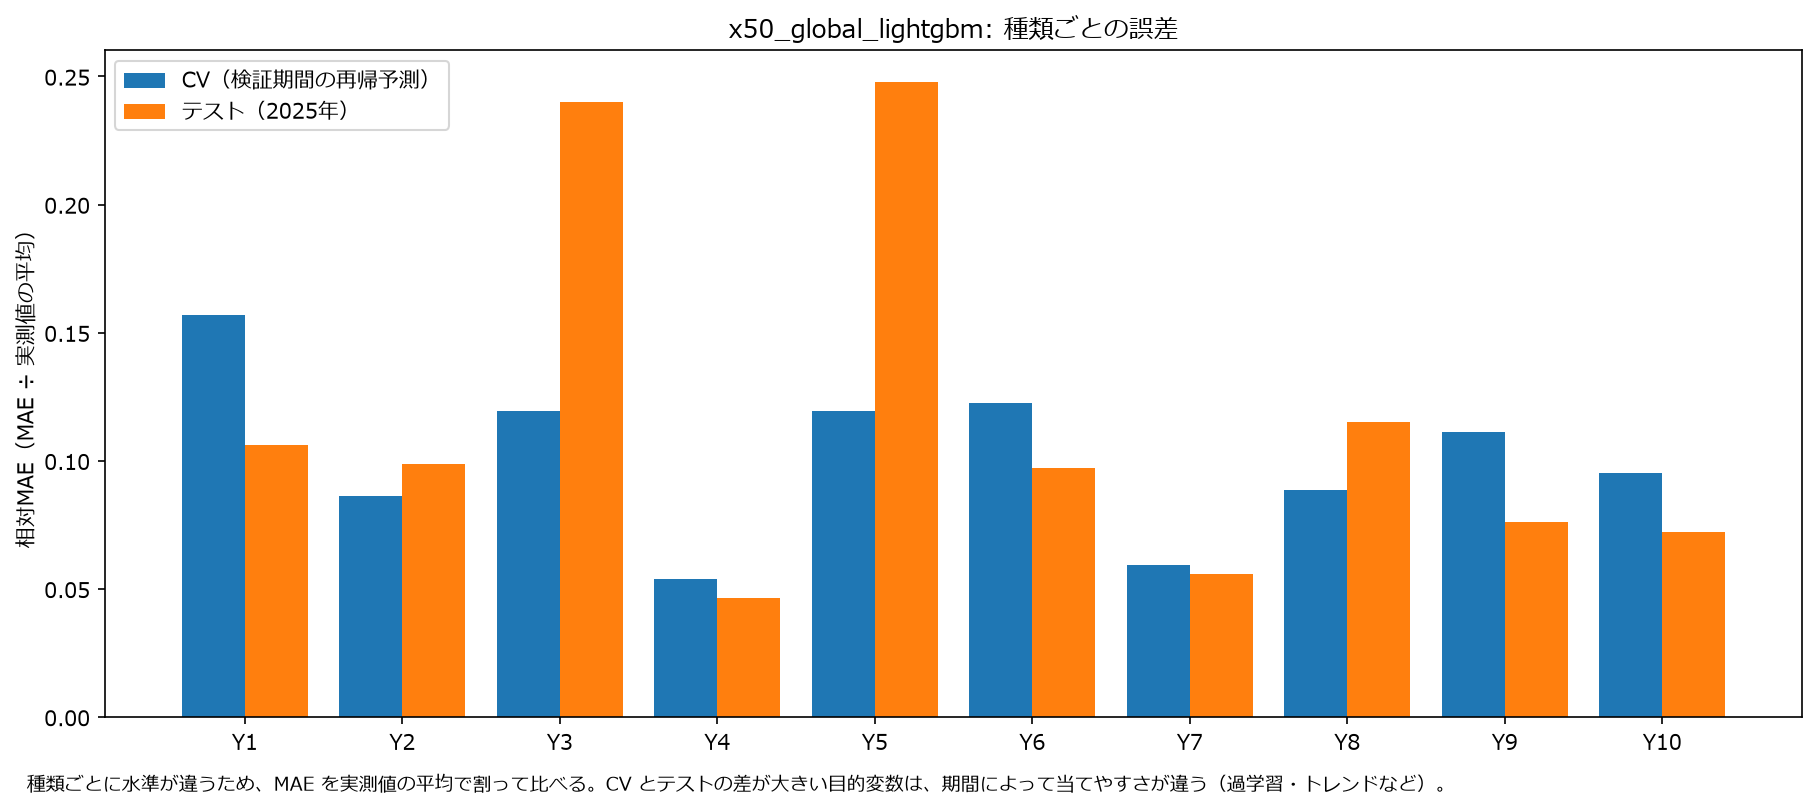

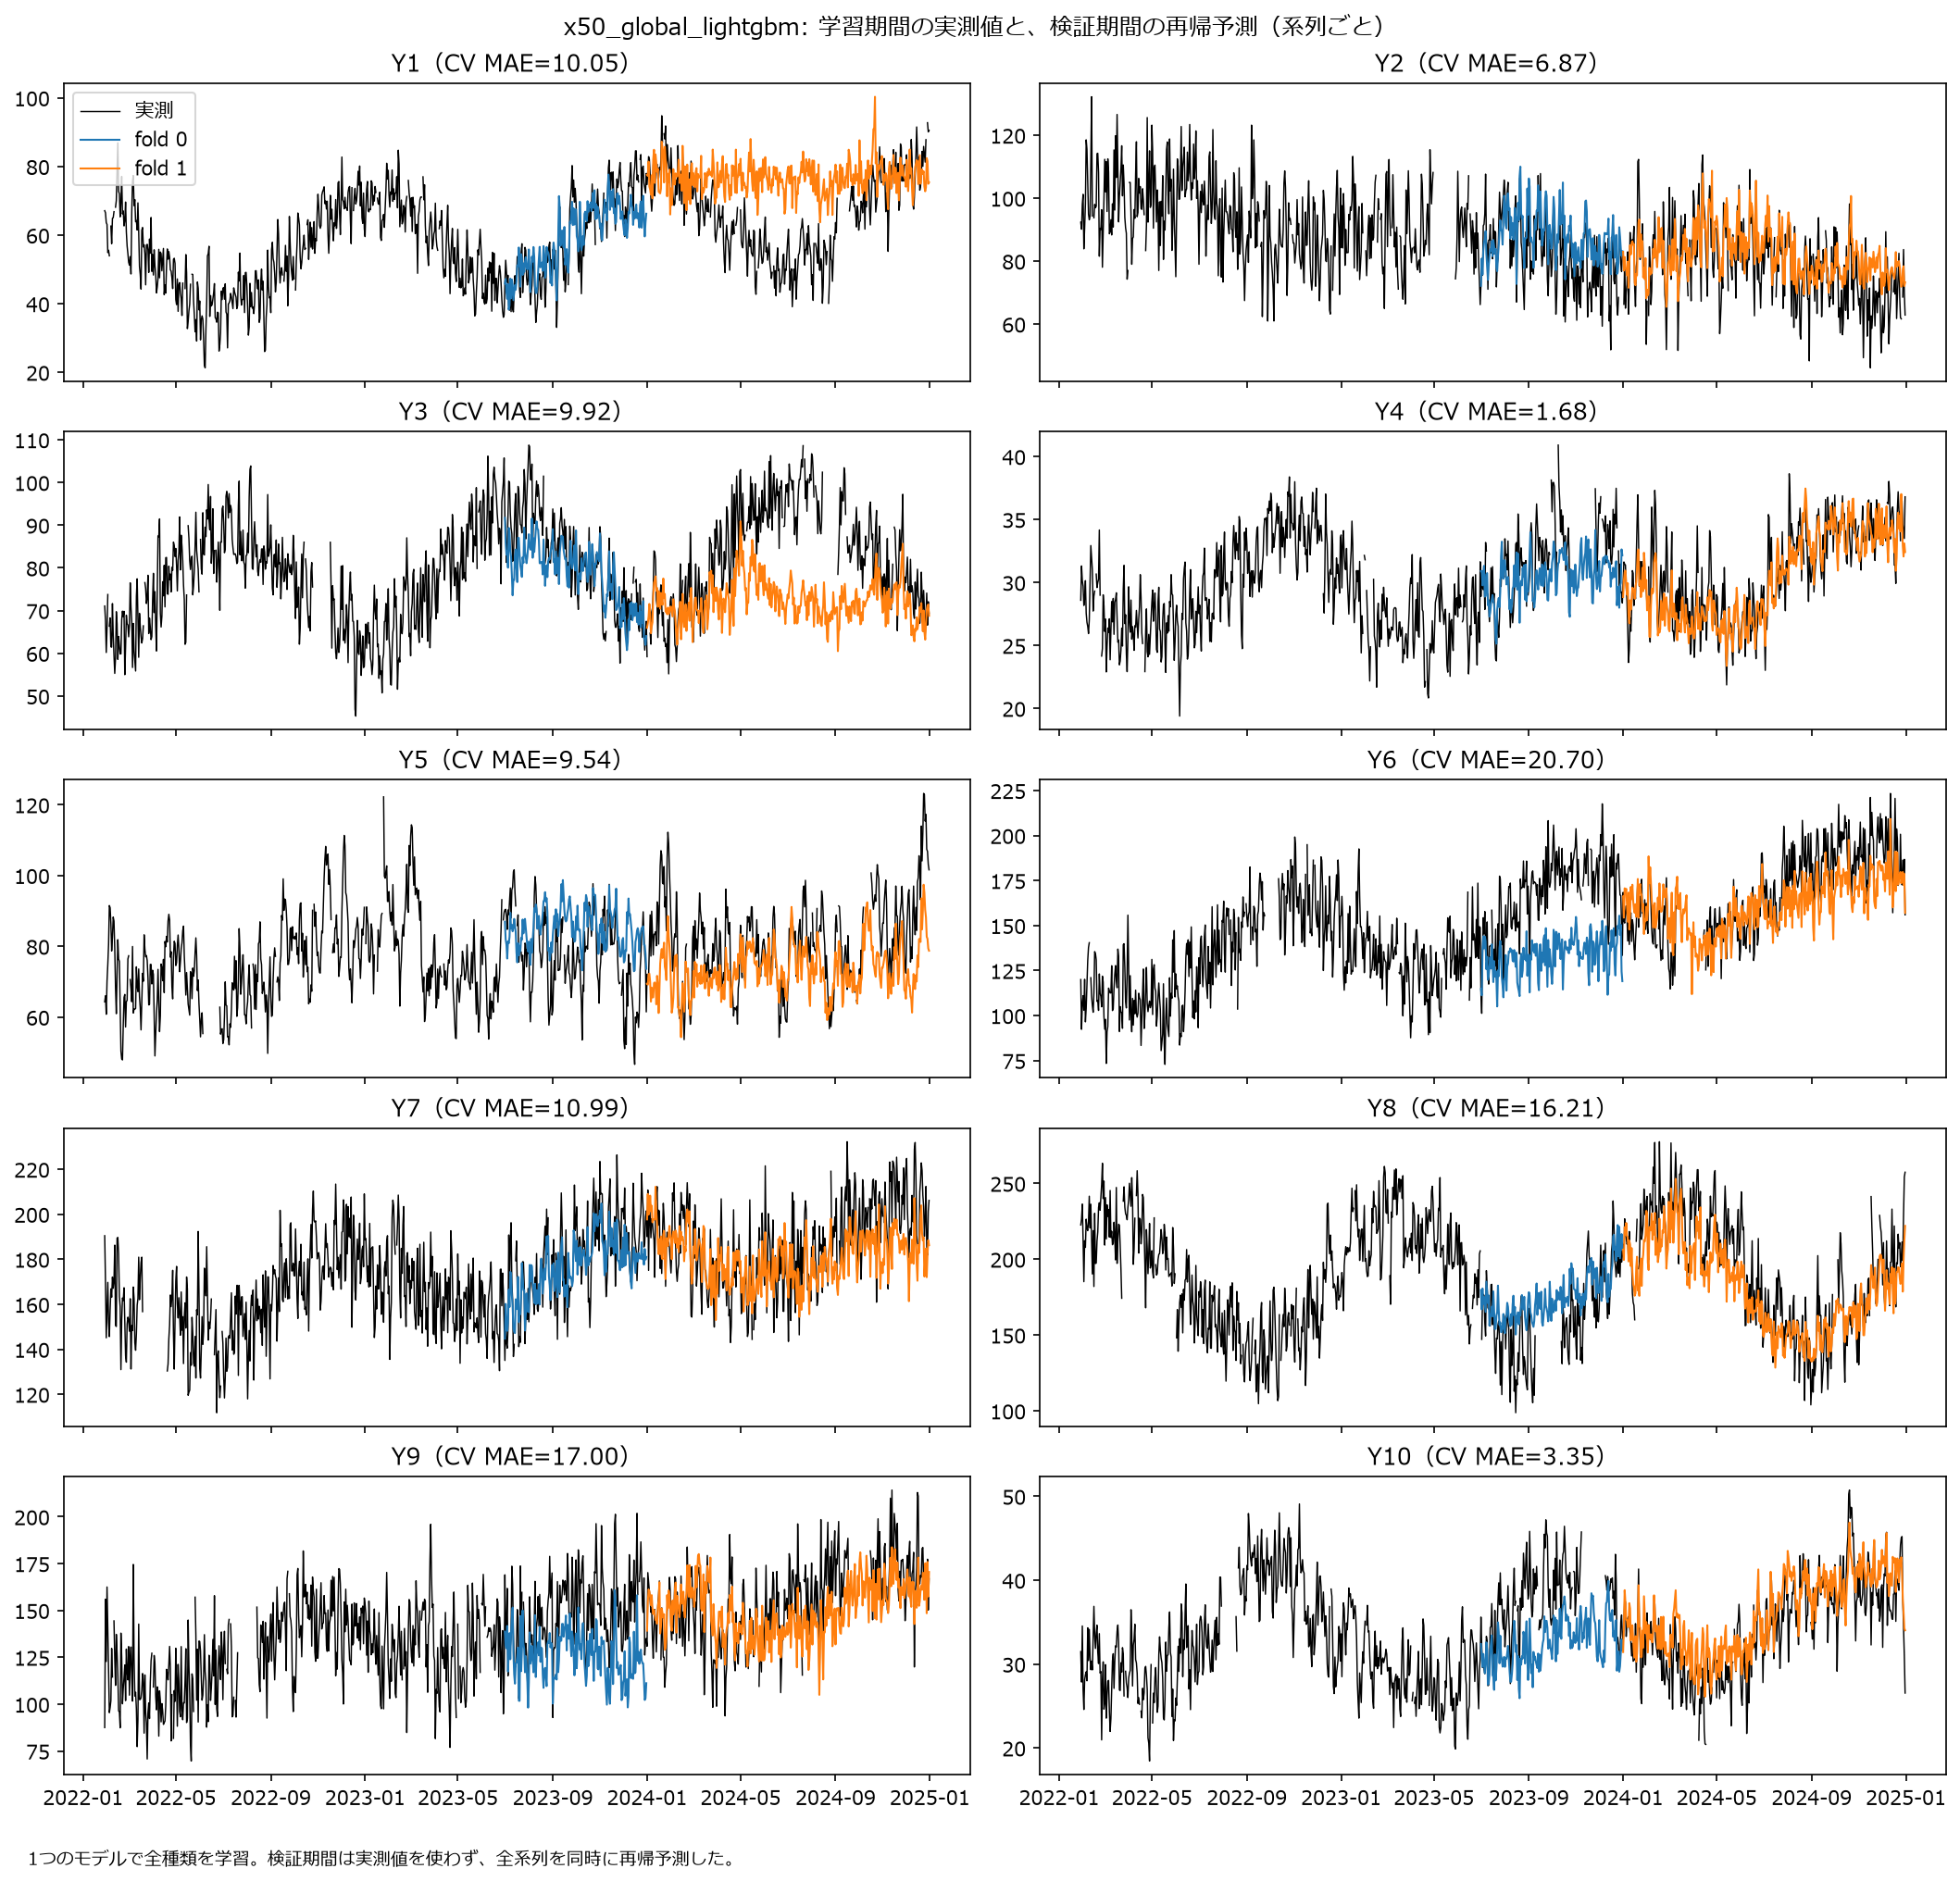

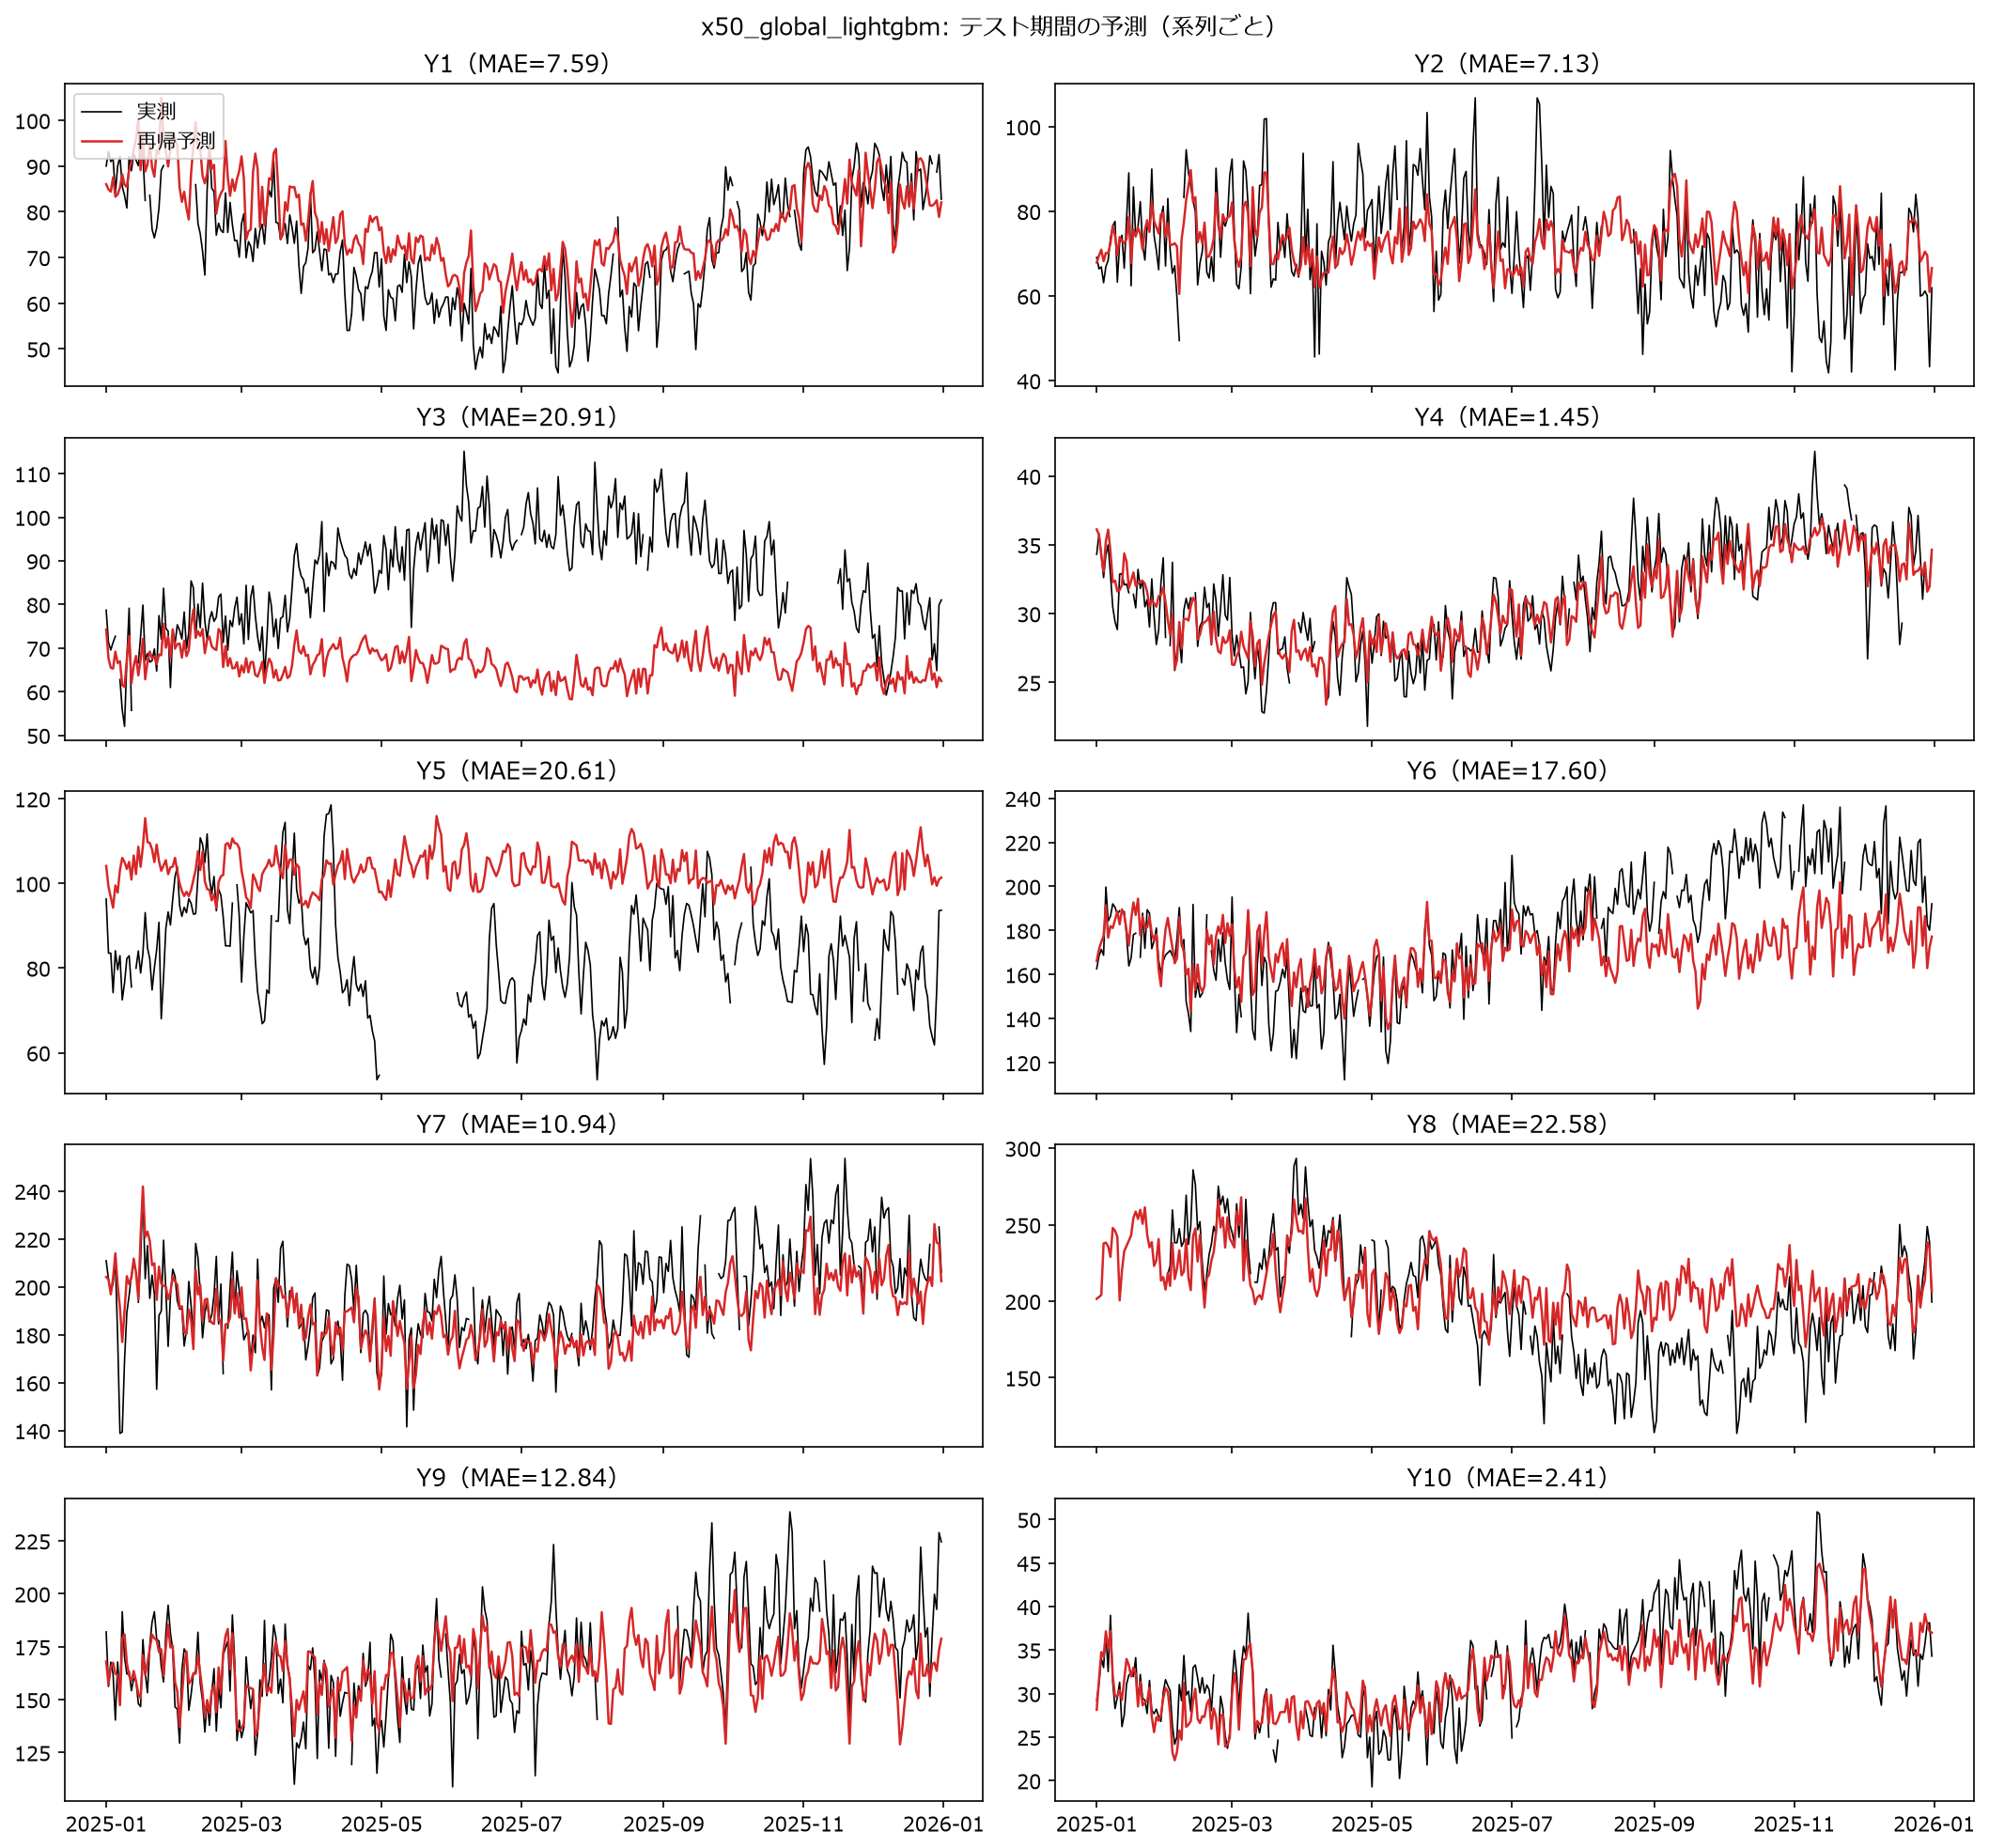

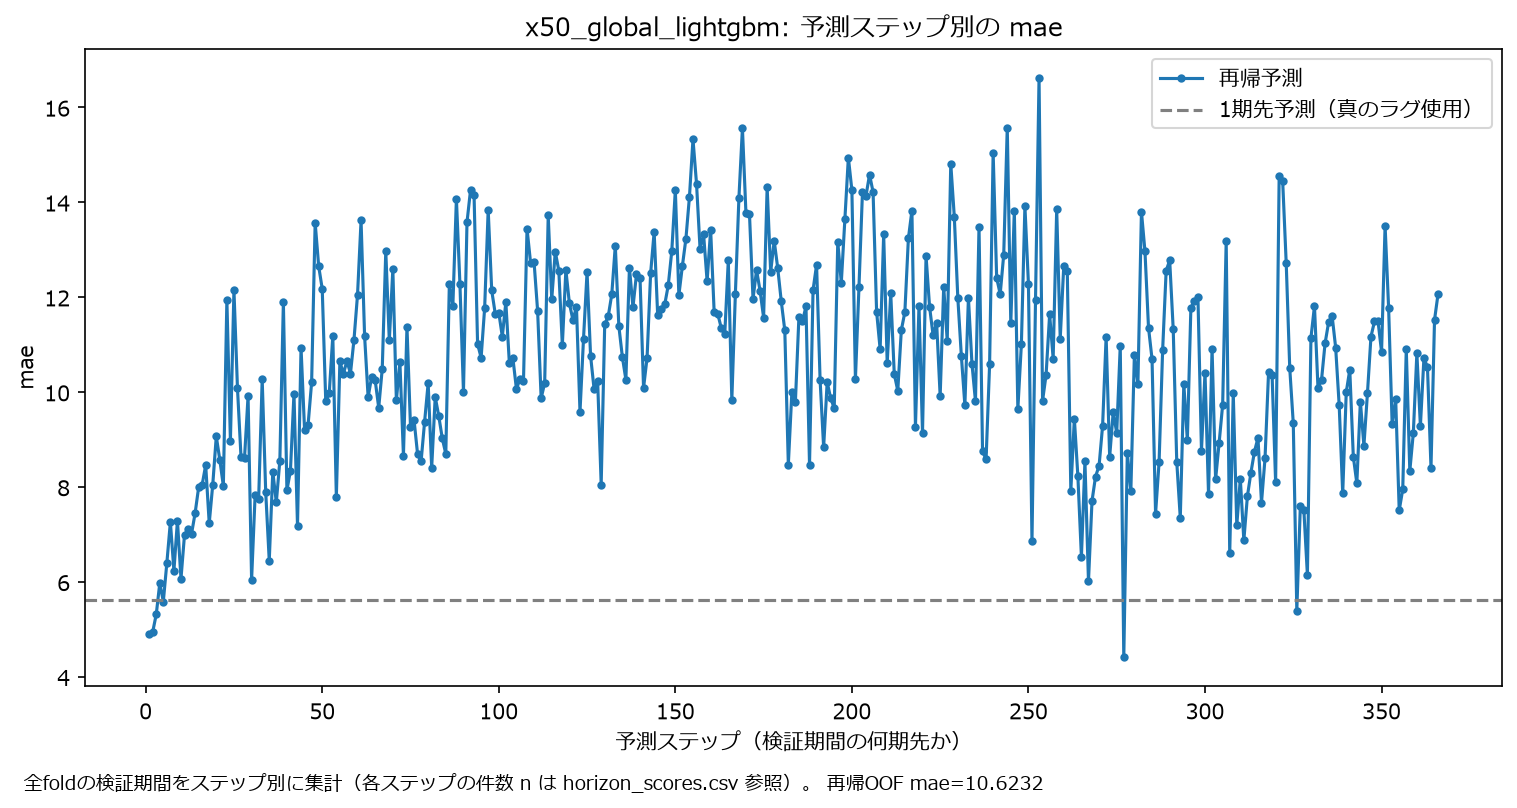

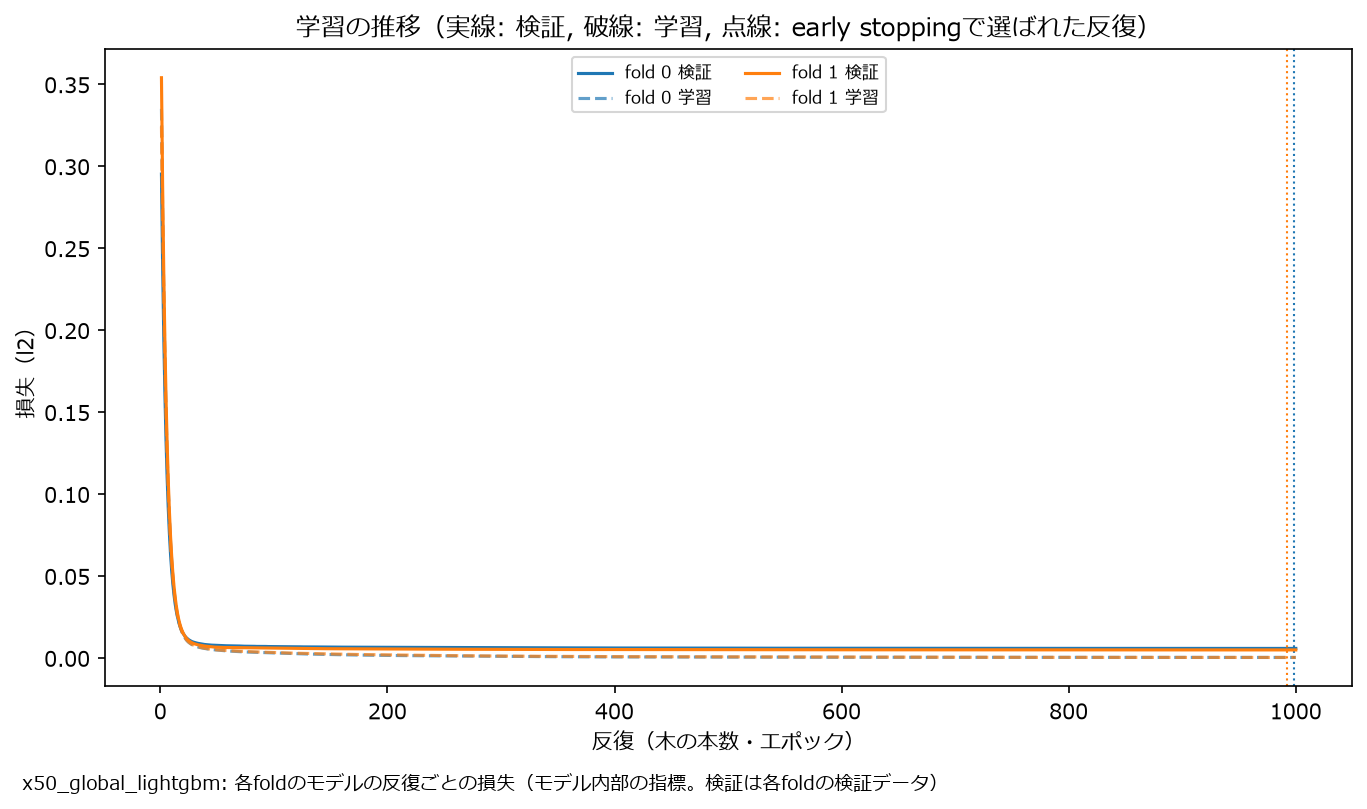

In [16]:
figures = out / "figures"
display(Image(filename=str(figures / "summary_mae.png"), width=950))
display(Image(filename=str(figures / "training_overview.png"), width=1000))
display(Image(filename=str(figures / "test_overview.png"), width=1000))
display(Image(filename=str(out / "horizon_error.png"), width=800))
display(Image(filename=str(out / "evaluation" / "training_history.png"), width=800))

## 5. SHAP によるモデル解釈

グローバルモデルを、各 fold の検証期間のデータで説明した SHAP 値（OOF SHAP）。モデルは目的変数の対数を予測するため、
SHAP 値も対数の尺度。

- **全体の重要度・beeswarm:** 全系列の行をまとめたもの。`Y_cat` は系列ID（どの種類か）。
- **種類ごとの重要度:** SHAP 値を行の系列で分けて平均し、種類ごとに合計1の割合にしたもの（004 の図と同じ形）。
  種類ごとに効く説明変数を、1つのモデルがどれだけ区別できているかを見る。

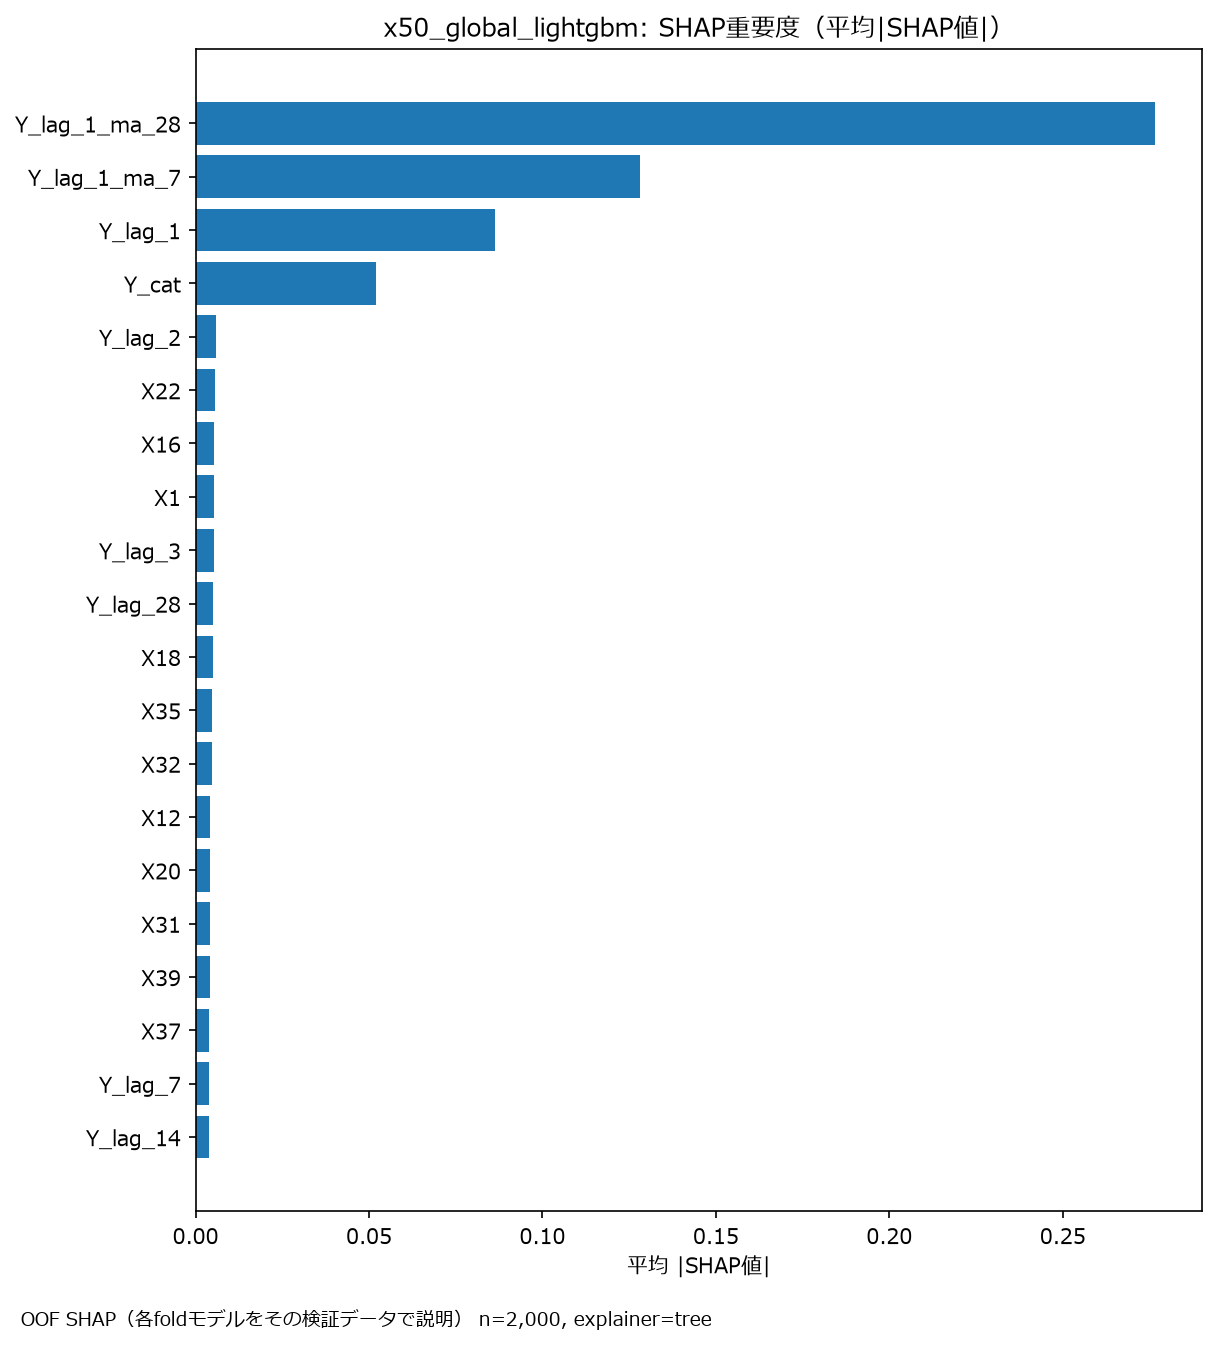

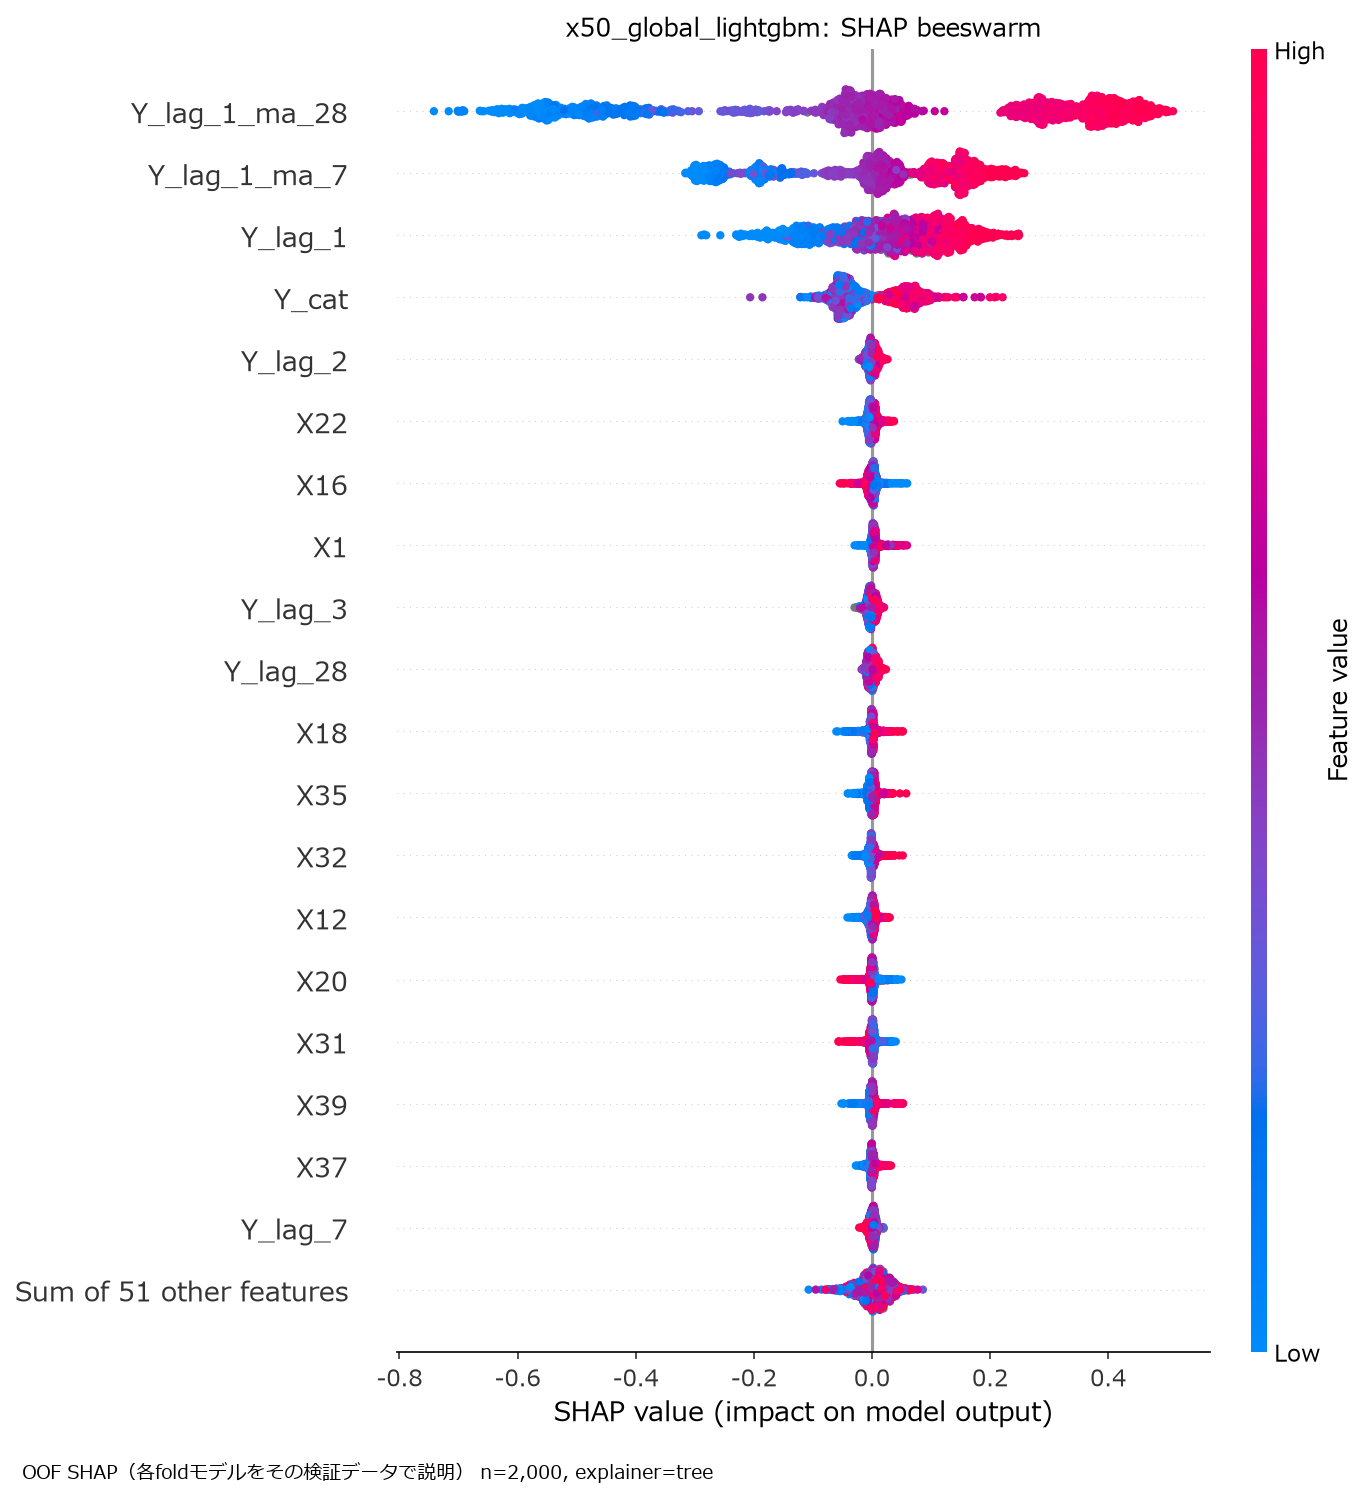

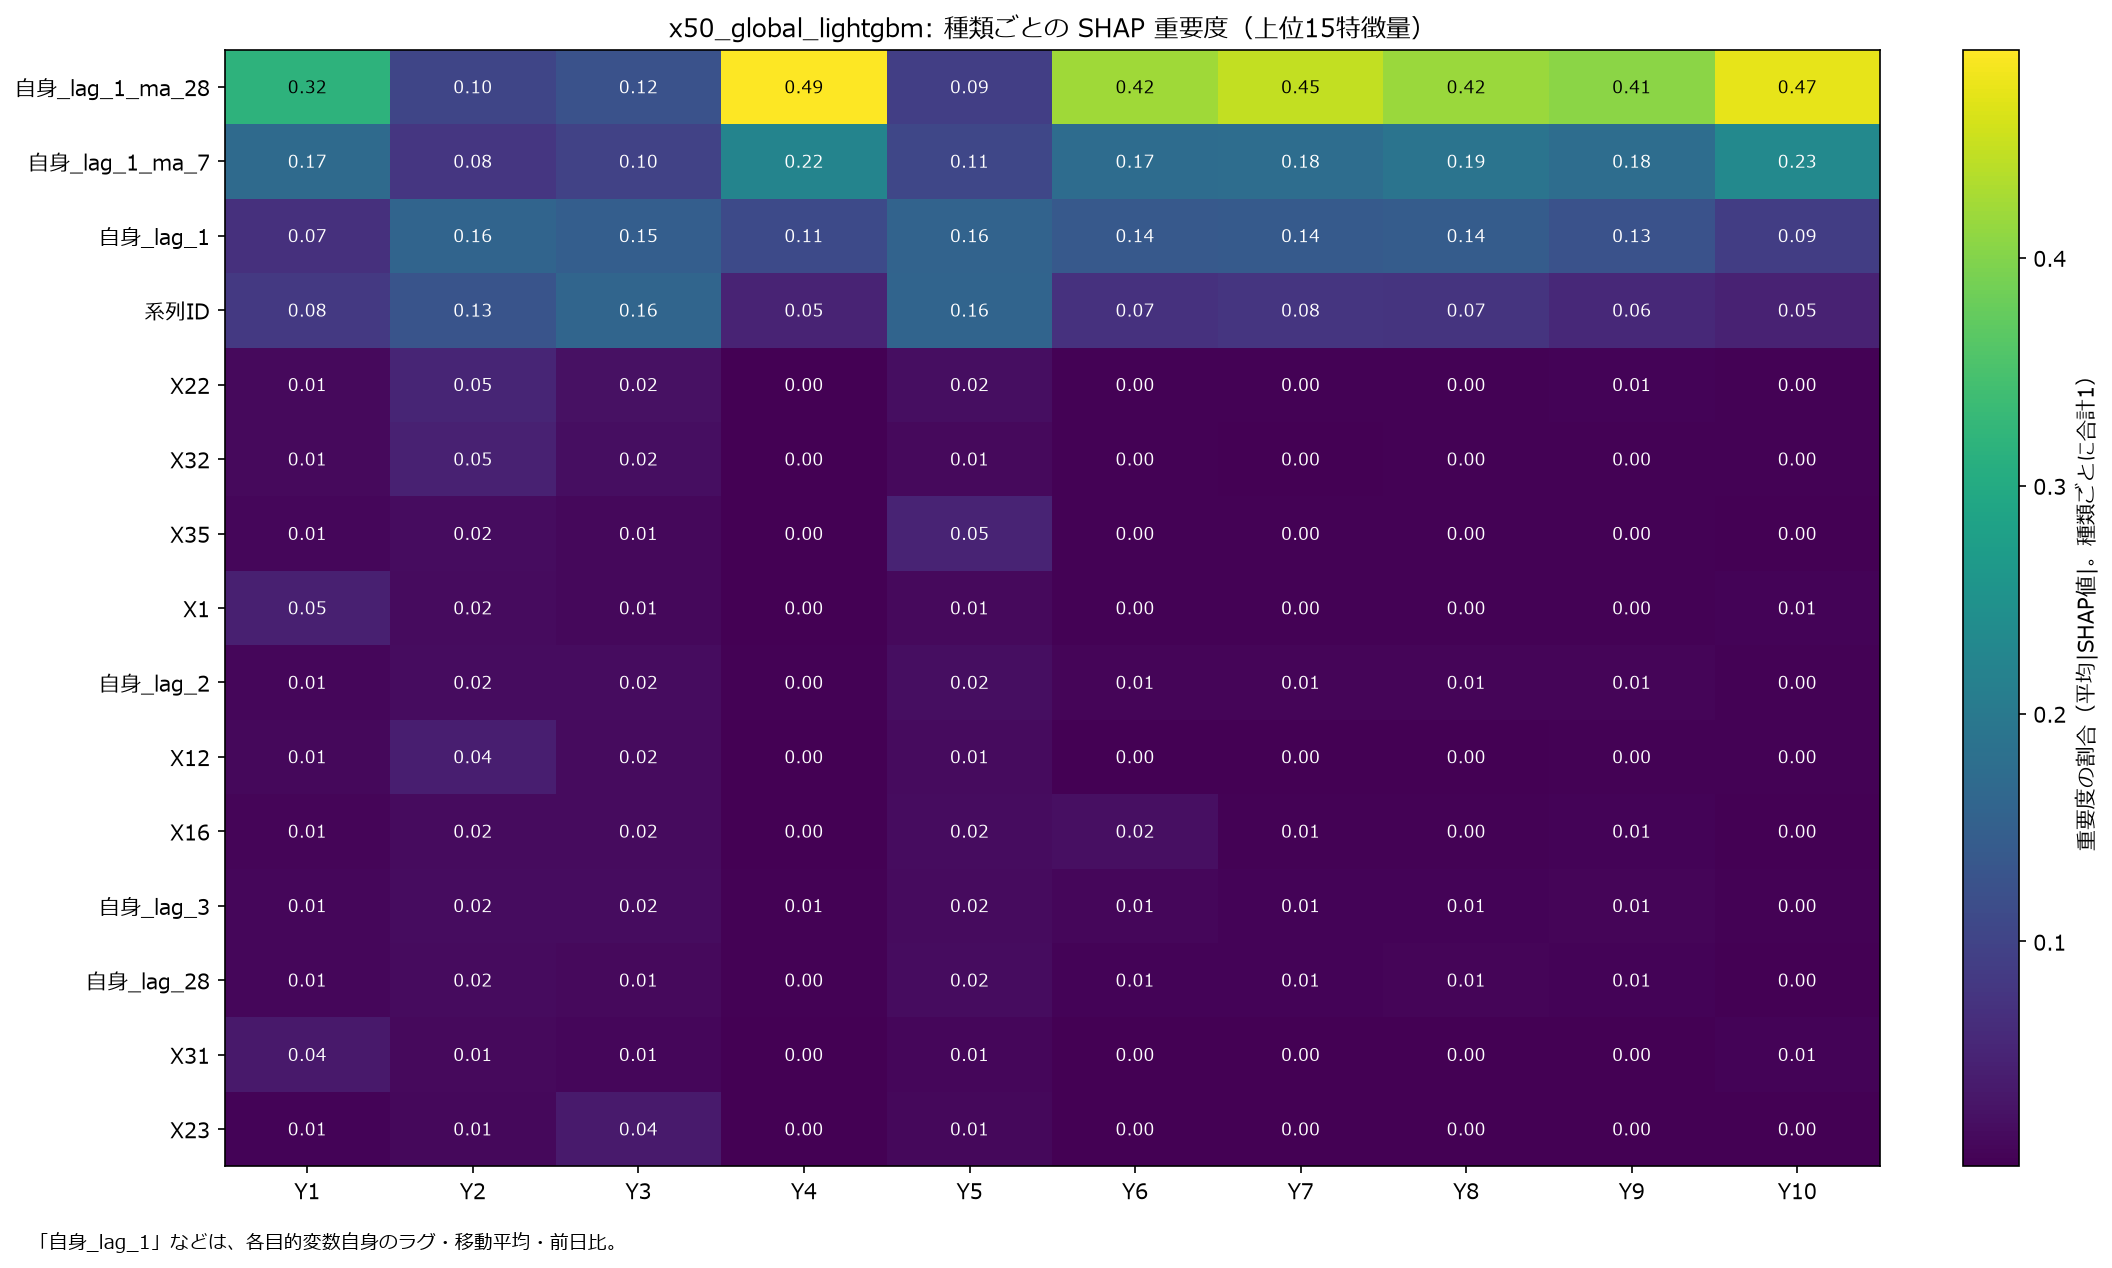

In [17]:
shap_dir = out / "shap"
display(Image(filename=str(shap_dir / "shap_importance_bar.png"), width=700))
display(Image(filename=str(shap_dir / "shap_beeswarm.png"), width=800))
display(Image(filename=str(figures / "shap_overview.png"), width=1000))

## 6. 004（種類ごとの個別モデル）との比較

`004_train_predict_x50.ipynb`（またはスクリプト `train_predict_x50.py`）の、同じモデルの最新の要約
（`outputs/experiments/x50_{モデル名}_summary/` の最新の実行）があれば、種類ごとの MAE を並べて比べる。

004 の要約: outputs/experiments/x50_lightgbm_summary/20261025_233029/summary.csv


,Y_cat,test_mae_個別モデル,test_mae_グローバル,差（グローバル − 個別）
0,Y1,3.896,7.595,3.699
1,Y2,4.598,7.125,2.527
2,Y3,16.084,20.911,4.827
3,Y4,1.239,1.446,0.208
4,Y5,6.970,20.614,13.644
5,Y6,11.429,17.596,6.167
6,Y7,8.134,10.939,2.805
7,Y8,10.834,22.579,11.745
8,Y9,11.641,12.839,1.198
9,Y10,2.058,2.406,0.348


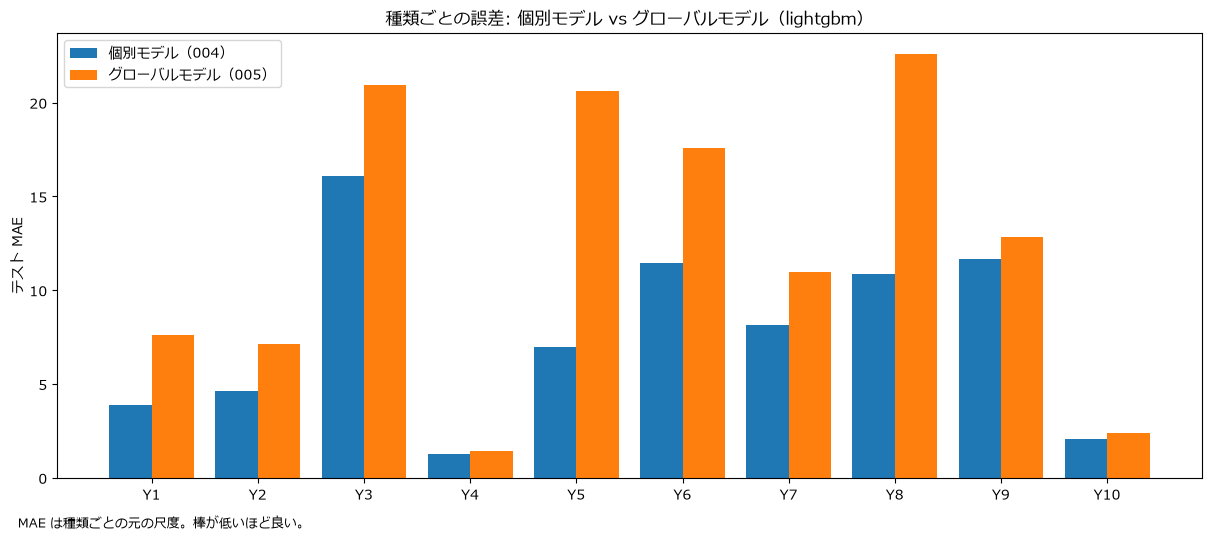

グローバルモデルの方が良い種類: 0 / 10
図: outputs/experiments/x50_global_lightgbm/20261025_234002_514727/figures/comparison_with_004.png


In [18]:
summaries_004 = sorted(
    (outputs_dir() / "experiments" / f"x50_{MODEL}_summary").glob("*/summary.csv")
)
if COMPARE_WITH_004 and summaries_004:
    individual = pd.read_csv(summaries_004[-1])
    # long 型に変える前の要約（種類の列名が target）にも対応する
    individual = individual.rename(columns={"target": CAT_COL})
    print(f"004 の要約: {shown(summaries_004[-1])}")
    metric = (
        "test_mae"
        if "test_mae" in summary.columns and "test_mae" in individual.columns
        else "cv_oof_mae"
    )
    comparison = individual[[CAT_COL, metric]].merge(
        summary[[CAT_COL, metric]], on=CAT_COL, suffixes=("_個別モデル", "_グローバル")
    )
    comparison["差（グローバル − 個別）"] = (
        comparison[f"{metric}_グローバル"] - comparison[f"{metric}_個別モデル"]
    )
    display(comparison.round(3))

    ensure_japanese_font()
    fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
    positions = np.arange(len(comparison))
    ax.bar(positions - 0.2, comparison[f"{metric}_個別モデル"], 0.4, label="個別モデル（004）")
    ax.bar(
        positions + 0.2, comparison[f"{metric}_グローバル"], 0.4, label="グローバルモデル（005）"
    )
    ax.set_xticks(positions, comparison[CAT_COL])
    ax.set_ylim(bottom=0)  # 棒グラフは0起点
    ax.set_ylabel("テスト MAE" if metric == "test_mae" else "CV MAE（再帰予測）")
    ax.set_title(f"種類ごとの誤差: 個別モデル vs グローバルモデル（{MODEL}）")
    ax.legend(loc="upper left")
    add_caption(fig, "MAE は種類ごとの元の尺度。棒が低いほど良い。")
    comparison_path = figures / "comparison_with_004.png"
    fig.savefig(comparison_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    better = int((comparison["差（グローバル − 個別）"] < 0).sum())
    print(f"グローバルモデルの方が良い種類: {better} / {len(comparison)}")
    print(f"図: {shown(comparison_path)}")
else:
    print("004 の結果が無いため比較を飛ばします（先に 004 を実行してください）")

## 7. 1つの種類の詳細（`DETAIL_TARGET`）

`modeling.evaluation` が系列ごとに作る、時系列の残差診断（推移・ヒストグラム・Q-Q・ACF/PACF・検定結果）。
再帰予測（recursive）の残差は誤差が積み重なるため自己相関が出やすい。モデルが取りこぼした過去の情報が無いかは、
1日先予測（onestep）の残差で判断する。

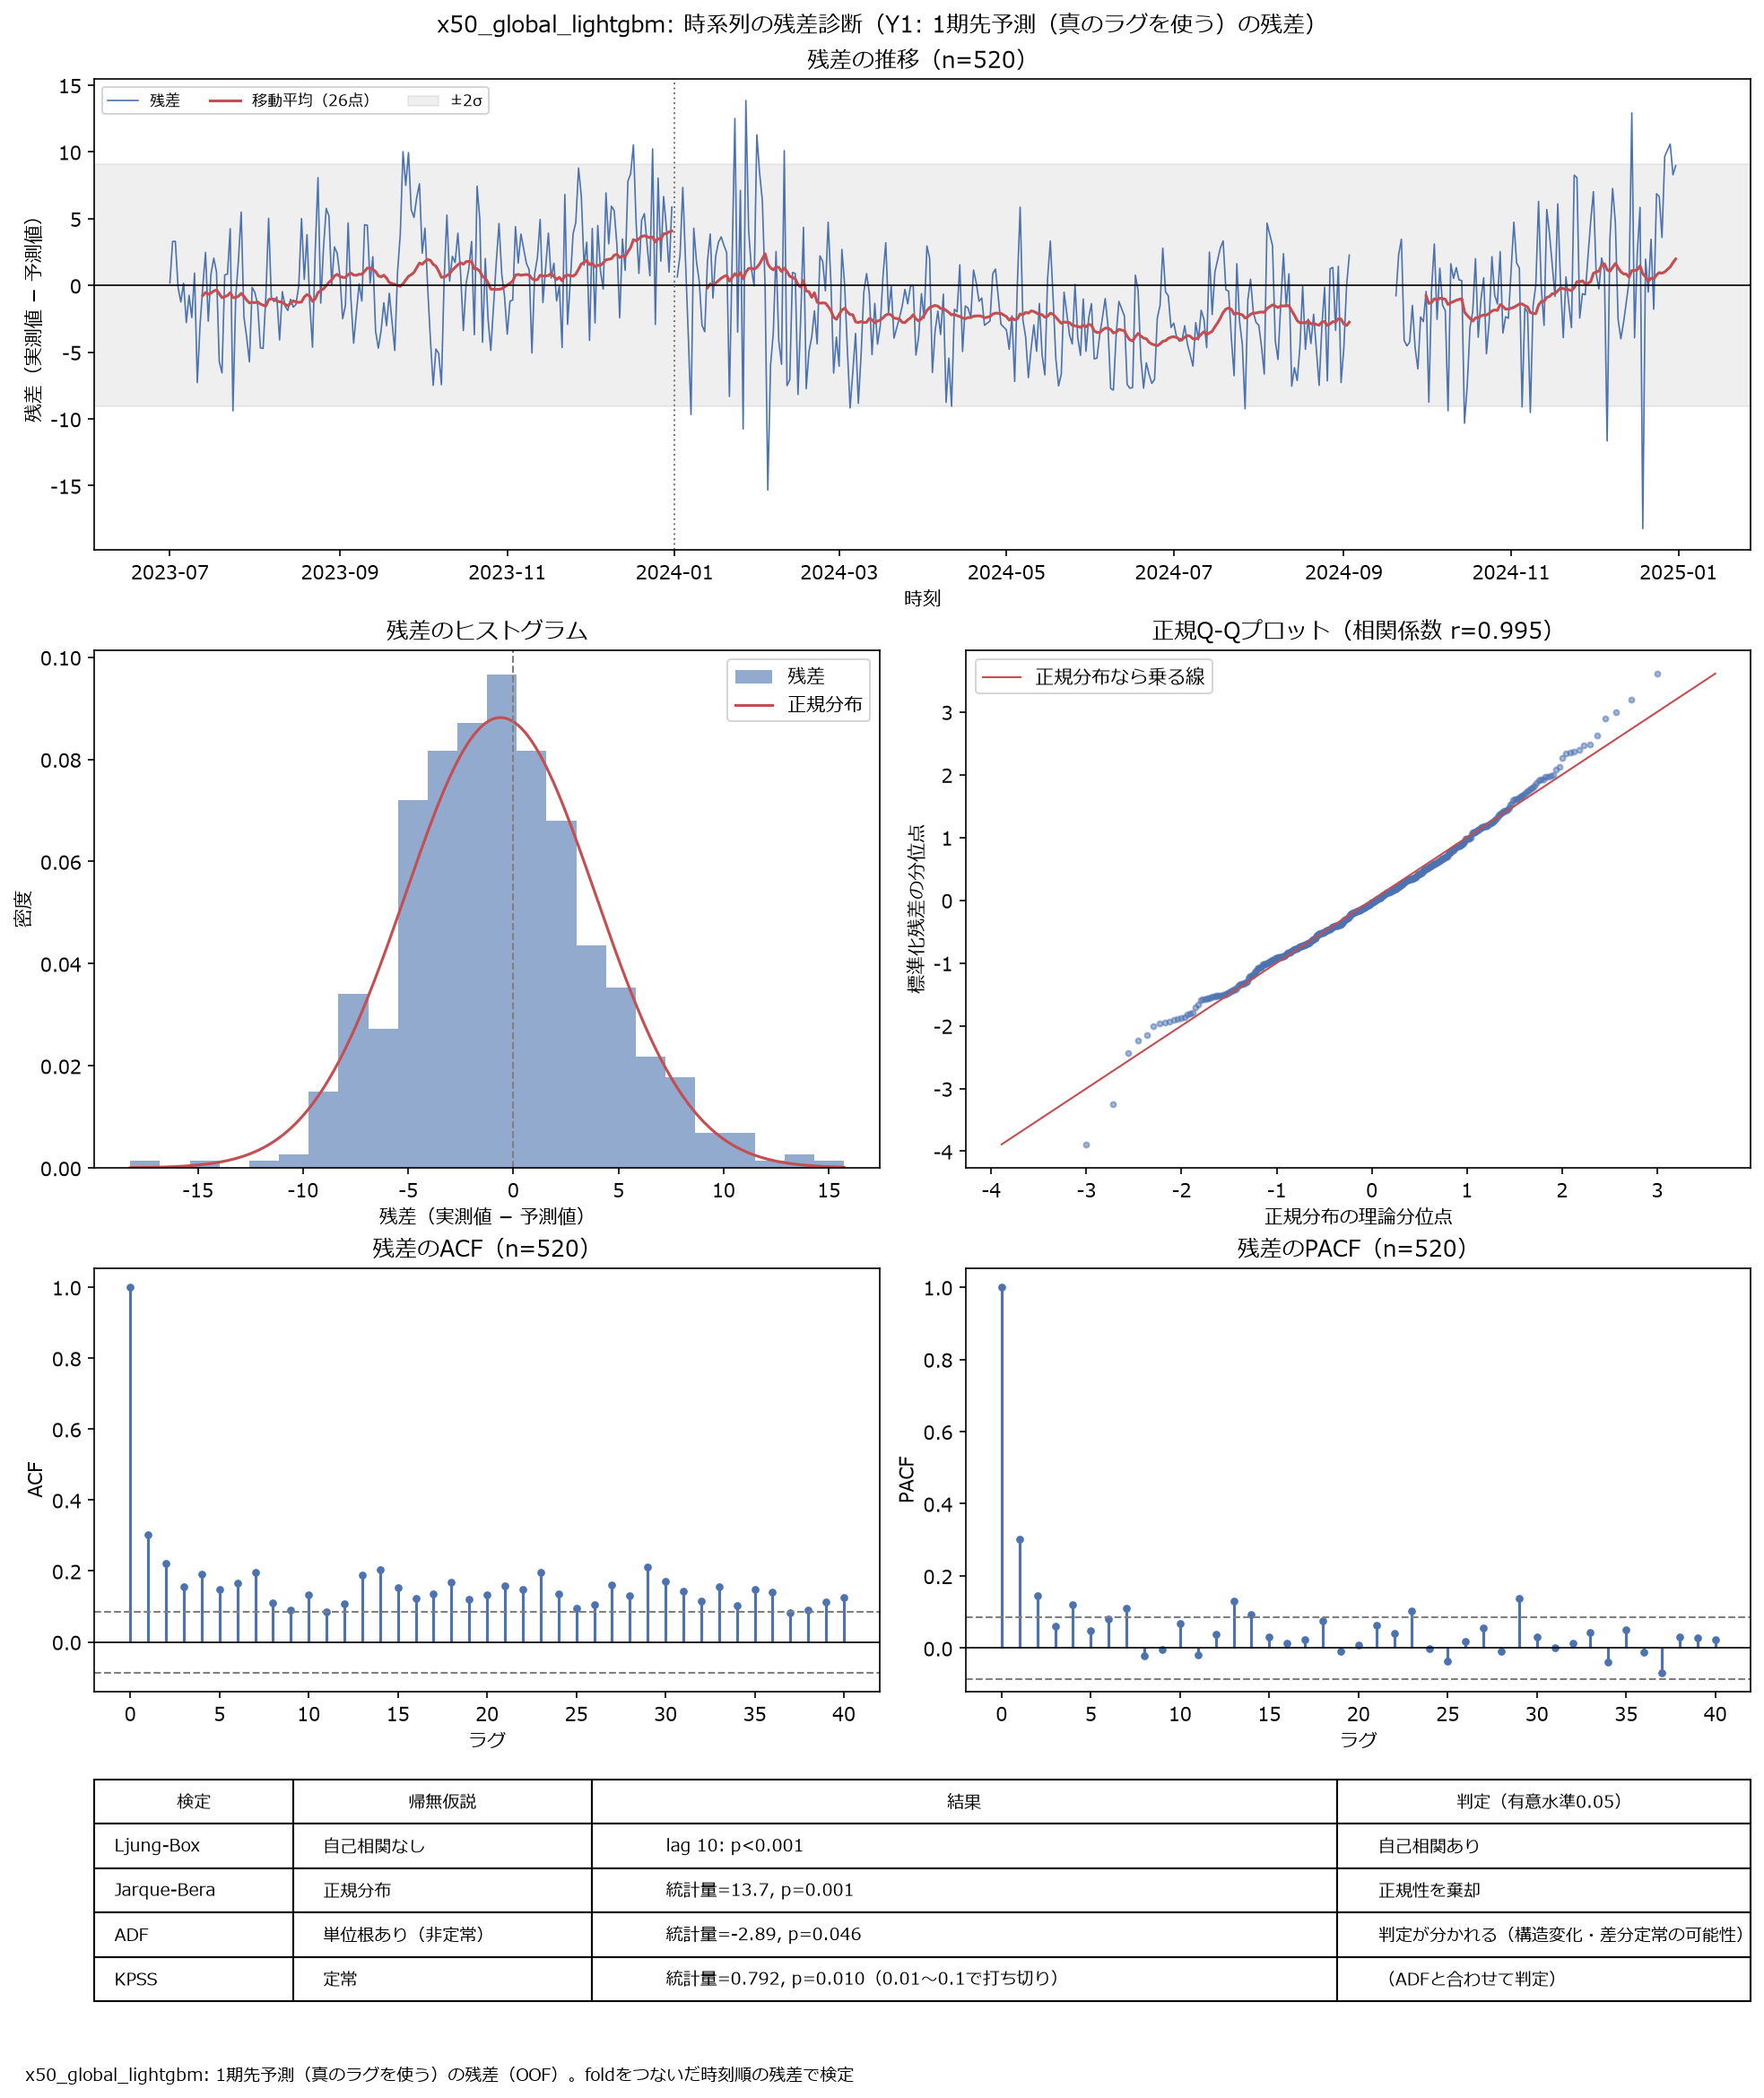

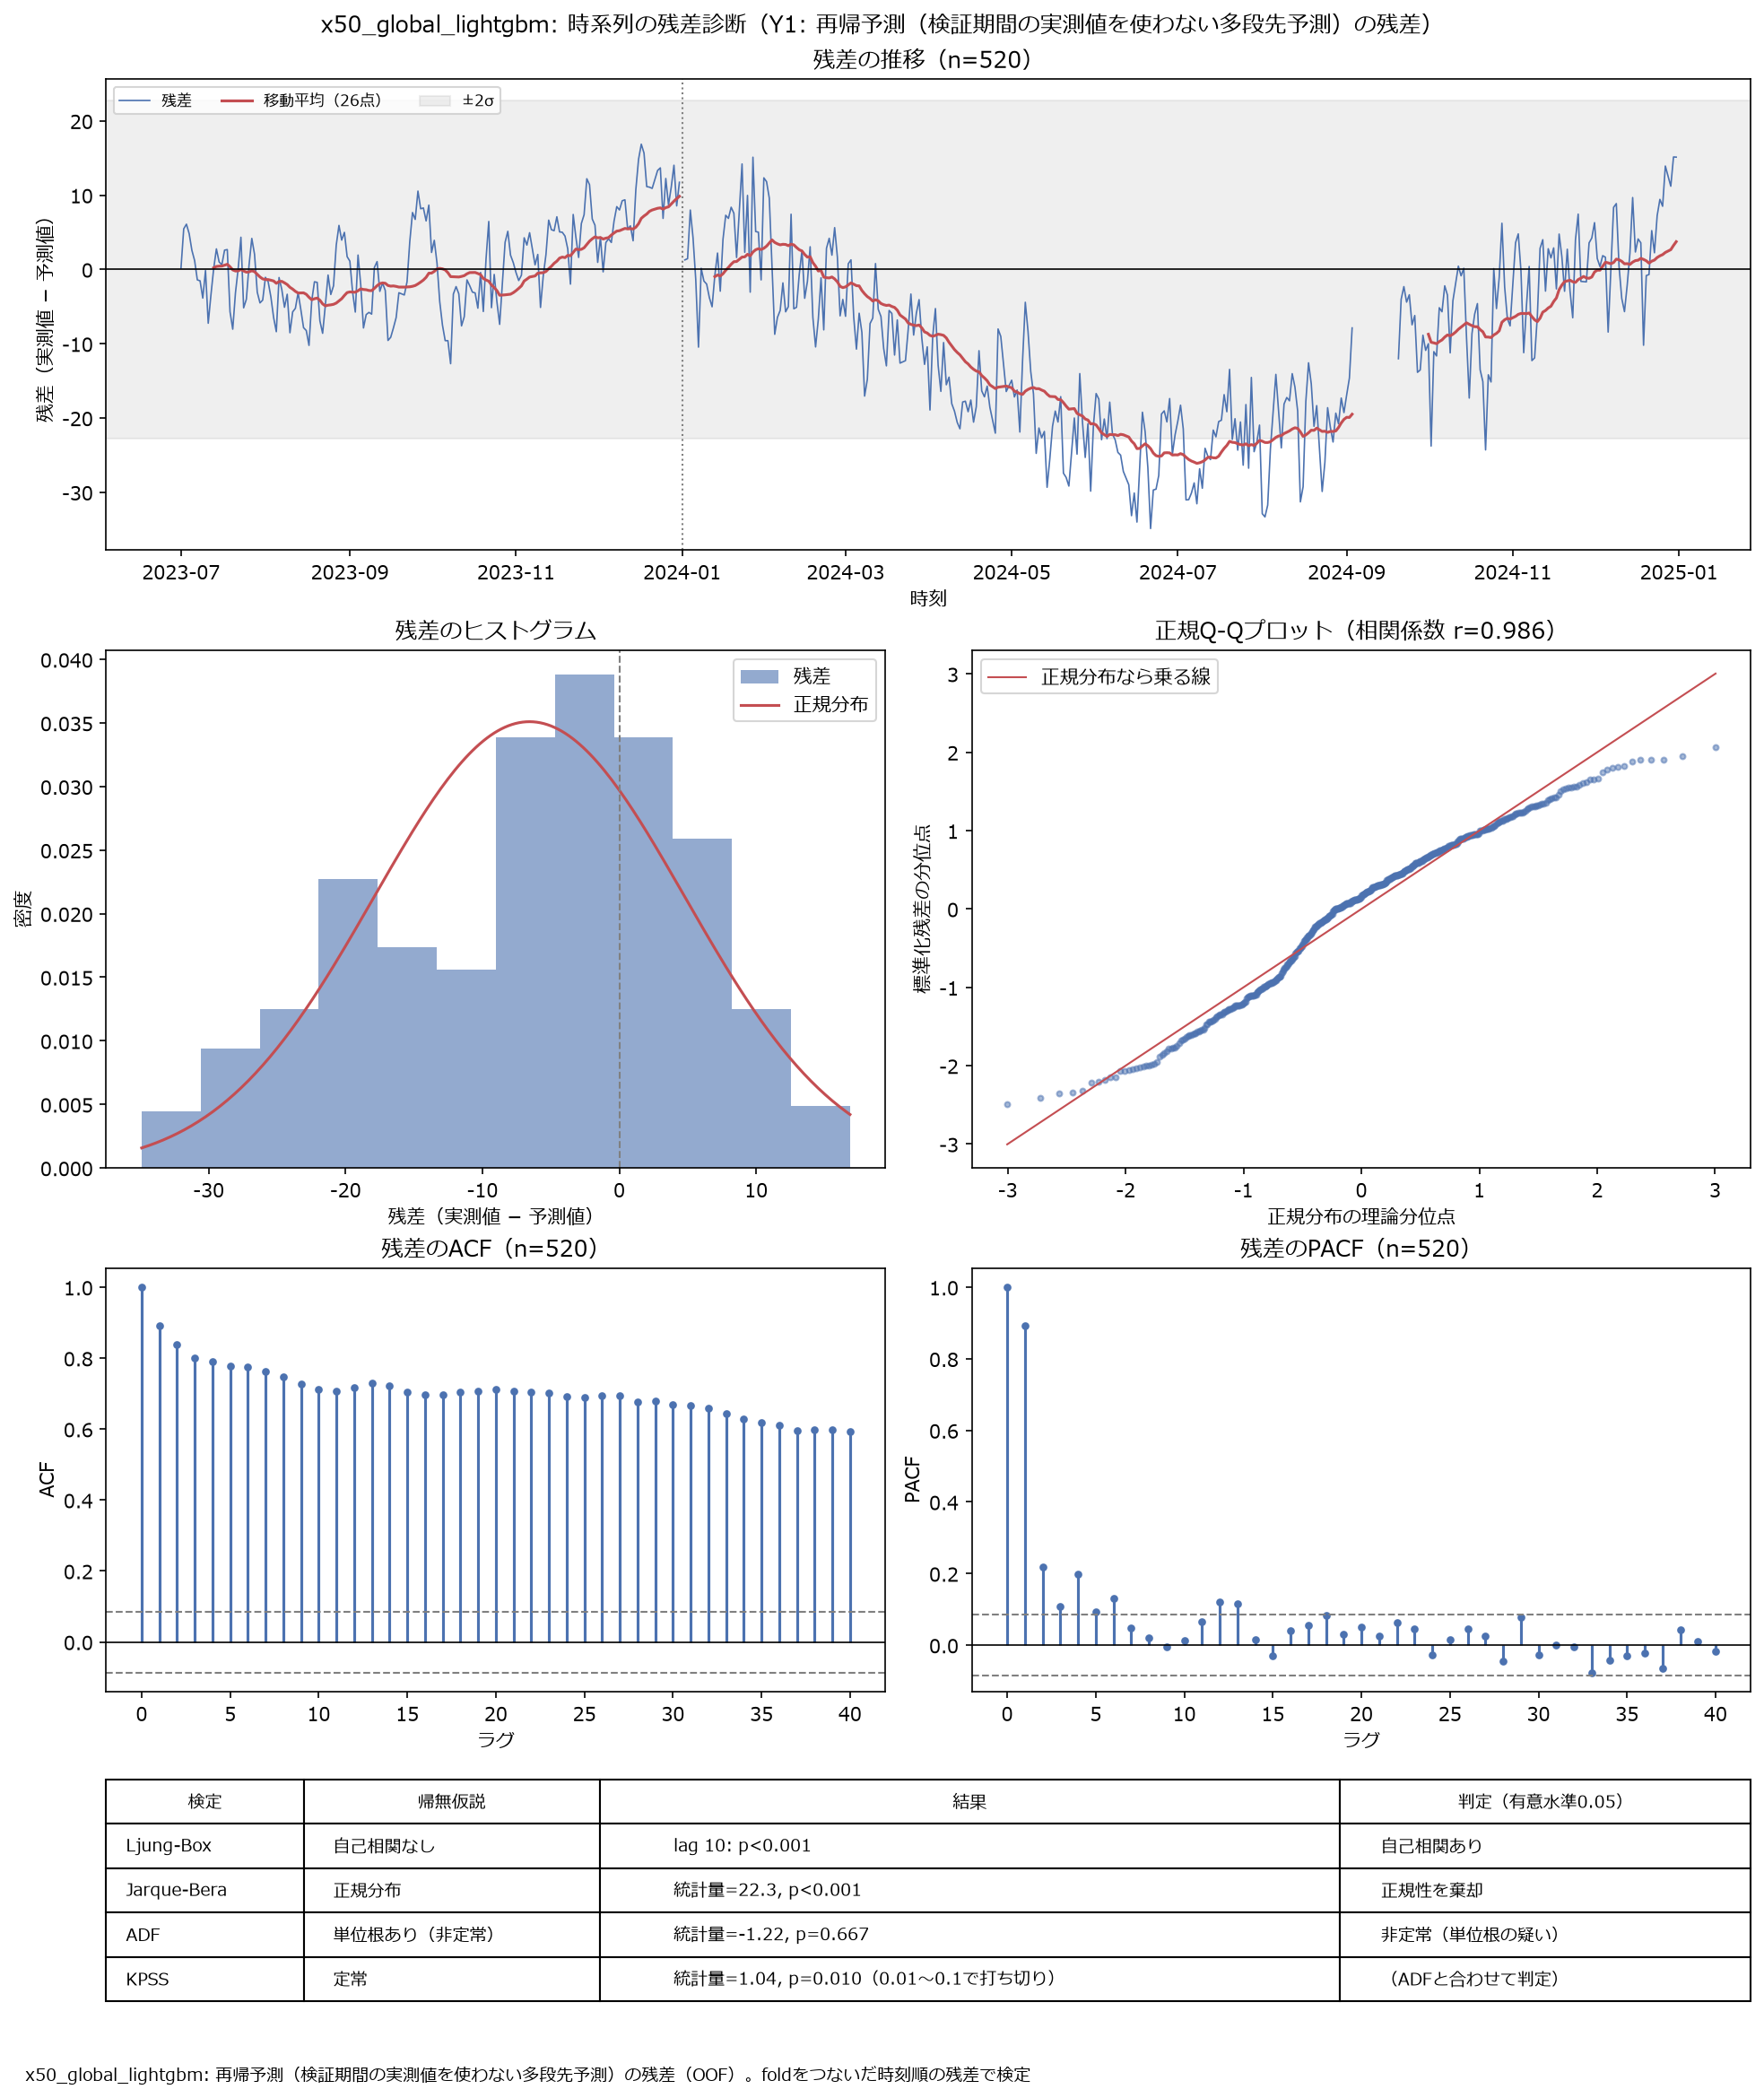

,date,Y_cat,pred,actual
0,2025-01-01,Y1,86.033165,90.004803
10,2025-01-02,Y1,84.893219,93.198048
20,2025-01-03,Y1,84.413490,90.977363
30,2025-01-04,Y1,87.514816,91.699246
40,2025-01-05,Y1,83.290837,84.084049


In [19]:
for kind in ("onestep", "recursive"):
    path = out / "evaluation" / f"residual_diagnostics__{kind}__{DETAIL_TARGET}.png"
    display(Image(filename=str(path), width=850))
detail = run.predictions[run.predictions[CAT_COL] == DETAIL_TARGET]
detail.head()

## まとめ

- long 型（1行 = 日付 × 種類）の学習データで、種類の列 `Y_cat` を系列IDとして特徴量に加えた1つのモデル
  （グローバルモデル）で学習・再帰予測した。各行の目的変数の特徴量は、その種類自身のラグ等だけから作っている
  （003 のCSVの値と一致することを確認）。
- CV は本番と同じ条件（検証期間の実測値を使わない、全系列同時の再帰予測）で評価している。
- ログはファイル（`outputs/logs/`、出力ディレクトリの `run.log`）と MLflow（全体・種類ごとの MAE、図、予測）に残している。

**注意点**

- 学習の早期終了・チューニングの指標（MAE）は全系列の行をまとめて計算するため、水準の高い種類の誤差の影響が大きい。
- 種類ごとに効く説明変数が違うデータでは、グローバルモデルはその違いを系列IDとの組み合わせで学ぶ必要があり、
  個別モデルより不利になりやすい（ダミーデータでは Yk に Xk 系だけが効く）。似た性質の種類が多い・各種類の
  データが少ない場合は、グローバルモデルが有利になりやすい。
- 目的変数が欠損の日は、CV・テストの評価から除いている（評価した日数はログ・`test_scores.csv` の `n`）。
  長い連続した欠損の直後は、ラグ・移動平均が欠損または少ない観測値から作られるため、予測が不安定になりやすい。
- SHAP は検証期間（OOF）での説明。テスト期間のモデル（学習データ全体で学習し直したもの）とは、学習に使った期間が違う。